<a href="https://colab.research.google.com/github/Jimenamatzui98/Portfolio/blob/master/Project__BigData.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import RobustScaler

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Dataframe gathering (Pollulants + meteorological conditions)

In [ ]:
RH = pd.read_excel('/content/drive/MyDrive/Big Data/2024RH.xls')
Temp = pd.read_excel('/content/drive/MyDrive/Big Data//2024TMP.xls')
WSP = pd.read_excel('/content/drive/MyDrive/Big Data//2024WSP.xls')
CO = pd.read_excel('/content/drive/MyDrive/Big Data//2024CO.xls')
WDR = pd.read_excel('/content/drive/MyDrive/Big Data//2024WDR.xls')
NO = pd.read_excel('/content/drive/MyDrive/Big Data/2024NO.xls')
NO2 = pd.read_excel('/content/drive/MyDrive/Big Data/2024NO2.xls')
NOx = pd.read_excel('/content/drive/MyDrive/Big Data/2024NOX.xls')
O3 = pd.read_excel('/content/drive/MyDrive/Big Data/2024O3.xls')
PM10 = pd.read_excel('/content/drive/MyDrive/Big Data/2024PM10.xls')
PM25 = pd.read_excel('/content/drive/MyDrive/Big Data/2024PM25.xls')
PMCO = pd.read_excel('/content/drive/MyDrive/Big Data/2024PMCO.xls')
SO2 = pd.read_excel('/content/drive/MyDrive/Big Data/2024SO2.xls')

-> Now we replace the null values (-99)


In [ ]:
RH = RH.replace(-99, np.nan)
Temp = Temp.replace(-99, np.nan)
WSP = WSP.replace(-99, np.nan)
CO = CO.replace(-99, np.nan)
WDR = WDR.replace(-99, np.nan)
NO = NO.replace(-99, np.nan)
NO2 = NO2.replace(-99, np.nan)
NOx = NOx.replace(-99, np.nan)
O3 = O3.replace(-99, np.nan)
PM10 = PM10.replace(-99, np.nan)
PM25 = PM25.replace(-99, np.nan)
PMCO = PMCO.replace(-99, np.nan)
SO2 = SO2.replace(-99, np.nan)

Create a function to "transpose" the stations

In [ ]:
def melt_df(df, value_name):
    station_cols = [c for c in df.columns if c not in ['FECHA', 'HORA']]
    return df.melt(
        id_vars=['FECHA', 'HORA'],
        value_vars=station_cols,
        var_name='STATION',
        value_name=value_name
    )

In [ ]:
temp_long = melt_df(Temp, 'temperature')
rh_long   = melt_df(RH, 'relative humidity')
ws_long   = melt_df(WSP, 'wind speed')
wd_long   = melt_df(WDR, 'wind direction')

In [ ]:
CO_long = melt_df(CO, 'CO')
NO_long = melt_df(NO, 'NO')
NO2_long = melt_df(NO2, 'NO2')
NOx_long = melt_df(NOx, 'NOx')
O3_long = melt_df(O3, '03')
PM10_long = melt_df(PM10, 'PM10')
PM25_long = melt_df(PM25, 'PM25')
PMCO_long = melt_df(PMCO, 'PMCO')
SO2_long = melt_df(SO2, 'SO2')

Merging dataset

In [ ]:
merged_meteorological = temp_long \
    .merge(rh_long, on=['FECHA', 'HORA', 'STATION'], how='outer') \
    .merge(ws_long, on=['FECHA', 'HORA', 'STATION'], how='outer') \
    .merge(wd_long, on=['FECHA', 'HORA', 'STATION'], how='outer')

In [ ]:
merged_meteorological = merged_meteorological.sort_values(['FECHA', 'HORA', 'STATION']).reset_index(drop=True)
measurement_cols = ['TEMPERATURE', 'RELATIVE_HUMIDITY', 'WIND_SPEED', 'WIND_DIRECTION']

In [ ]:
df_pollulants_meteorological = temp_long \
    .merge(rh_long, on=['FECHA', 'HORA', 'STATION'], how='outer') \
    .merge(ws_long, on=['FECHA', 'HORA', 'STATION'], how='outer') \
    .merge(wd_long, on=['FECHA', 'HORA', 'STATION'], how='outer') \
    .merge(CO_long, on=['FECHA', 'HORA', 'STATION'], how='outer') \
    .merge(NO_long, on=['FECHA', 'HORA', 'STATION'], how='outer') \
    .merge(NO2_long, on=['FECHA', 'HORA', 'STATION'], how='outer') \
    .merge(NOx_long, on=['FECHA', 'HORA', 'STATION'], how='outer') \
    .merge(O3_long, on=['FECHA', 'HORA', 'STATION'], how='outer') \
    .merge(PM10_long, on=['FECHA', 'HORA', 'STATION'], how='outer') \
    .merge(PM25_long, on=['FECHA', 'HORA', 'STATION'], how='outer') \
    .merge(PMCO_long, on=['FECHA', 'HORA', 'STATION'], how='outer') \
    .merge(SO2_long, on=['FECHA', 'HORA', 'STATION'], how='outer')

-> deleting stations outside of mexico city

In [ ]:
stations_to_remove = ["ACO", "ATI", "CHO", "CUT", "FAC", "FAR", "INN", "LPR", "LLA", "MON", "NEZ", "SAG", "TLA", "TLI", "VIF", "XAL"]
df_pollulants_meteorological= df_pollulants_meteorological[~df_pollulants_meteorological["STATION"].isin(stations_to_remove)]

Working dataset:

In [ ]:
airquality_pop = df_pollulants_meteorological.dropna(subset=["03"])
airquality_pop.info()

<class 'pandas.core.frame.DataFrame'>
Index: 120749 entries, 1 to 324925
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   FECHA              120749 non-null  datetime64[ns]
 1   HORA               120749 non-null  int64         
 2   STATION            120749 non-null  object        
 3   temperature        61969 non-null   float64       
 4   relative humidity  71620 non-null   float64       
 5   wind speed         68403 non-null   float64       
 6   wind direction     68403 non-null   float64       
 7   CO                 94409 non-null   float64       
 8   NO                 86925 non-null   float64       
 9   NO2                98473 non-null   float64       
 10  NOx                86925 non-null   float64       
 11  03                 120749 non-null  float64       
 12  PM10               62774 non-null   float64       
 13  PM25               67332 non-null   float64      

In [ ]:
airquality_pop['STATION'].unique()

array(['AJM', 'AJU', 'BJU', 'CAM', 'CCA', 'CUA', 'GAM', 'MER', 'PED',
       'SAC', 'TAH', 'UIZ', 'MGH', 'MPA', 'IZT', 'HGM', 'UAX'],
      dtype=object)

In [ ]:
airquality_pop.head()

,FECHA,HORA,STATION,temperature,relative humidity,wind speed,wind direction,CO,NO,NO2,NOx,03,PM10,PM25,PMCO,SO2,month
1,2024-01-01,1,AJM,6.0,57.0,3.5,320.0,0.23,0.0,10.0,10.0,11.0,44.0,33.0,11.0,5.0,2024-01
2,2024-01-01,1,AJU,1.0,99.0,0.9,54.0,NaN,NaN,NaN,NaN,43.0,NaN,NaN,NaN,NaN,2024-01
4,2024-01-01,1,BJU,12.0,56.0,0.8,173.0,1.18,NaN,43.0,NaN,3.0,62.0,42.0,20.0,NaN,2024-01
5,2024-01-01,1,CAM,NaN,NaN,NaN,NaN,1.15,4.0,41.0,45.0,5.0,67.0,46.0,21.0,7.0,2024-01
6,2024-01-01,1,CCA,NaN,NaN,NaN,NaN,0.88,7.0,31.0,38.0,9.0,NaN,NaN,NaN,3.0,2024-01


#EXPLORING

In [ ]:
RH.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8776 entries, 0 to 8775
Data columns (total 30 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   FECHA   8776 non-null   datetime64[ns]
 1   HORA    8776 non-null   int64         
 2   ACO     8776 non-null   int64         
 3   AJM     8776 non-null   int64         
 4   AJU     8776 non-null   int64         
 5   BJU     8776 non-null   int64         
 6   CHO     8776 non-null   int64         
 7   CUA     8776 non-null   int64         
 8   CUT     8776 non-null   int64         
 9   FAC     8776 non-null   int64         
 10  FAR     8776 non-null   int64         
 11  GAM     8776 non-null   int64         
 12  HGM     8776 non-null   int64         
 13  INN     8776 non-null   int64         
 14  LAA     8776 non-null   int64         
 15  MER     8776 non-null   int64         
 16  MGH     8776 non-null   int64         
 17  MON     8776 non-null   int64         
 18  MPA     

In [ ]:
RH.head()

,FECHA,HORA,ACO,AJM,AJU,BJU,CHO,CUA,CUT,FAC,...,PED,SAC,SAG,SFE,TAH,TLA,UAX,UIZ,VIF,XAL
0,2024-01-01,1,-99,57,99,56,-99,52,58,59,...,-99,61,67,-99,60,-99,-99,71,-99,-99
1,2024-01-01,2,-99,60,100,63,-99,55,60,65,...,-99,63,73,-99,58,-99,-99,74,-99,-99
2,2024-01-01,3,-99,63,100,65,-99,57,64,69,...,-99,66,71,-99,64,-99,-99,75,-99,-99
3,2024-01-01,4,-99,64,100,64,-99,58,66,73,...,-99,67,68,-99,64,-99,-99,79,-99,-99
4,2024-01-01,5,-99,65,100,66,-99,60,68,75,...,-99,67,73,-99,65,-99,-99,80,-99,-99


**There are 8760 hours per year but these datasets have 8776 counts for each parameter, trying to figure out why bellow**

- 2024 was a leap year meaning: 8,784 hours.
- considering the figure bellow, we assume that something happened with the measurements in some hours causing these data gaps


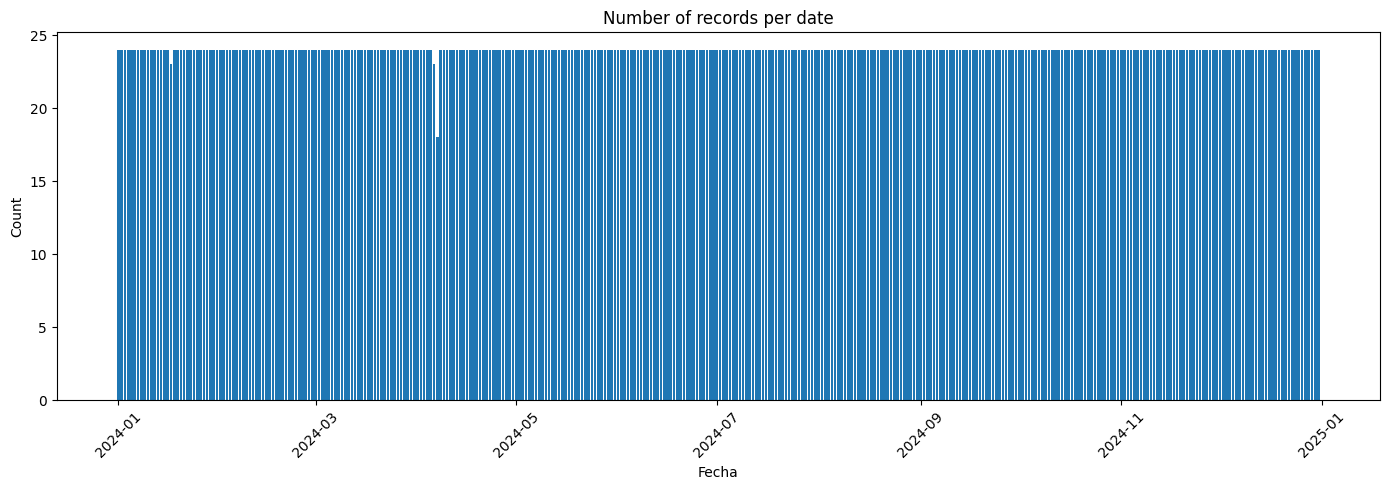

In [ ]:
fechas = RH['FECHA'].value_counts().sort_index()

plt.figure(figsize=(14, 5))
plt.bar(fechas.index, fechas.values)

plt.xlabel('Fecha')
plt.ylabel('Count')
plt.title('Number of records per date')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<Axes: xlabel='FECHA'>

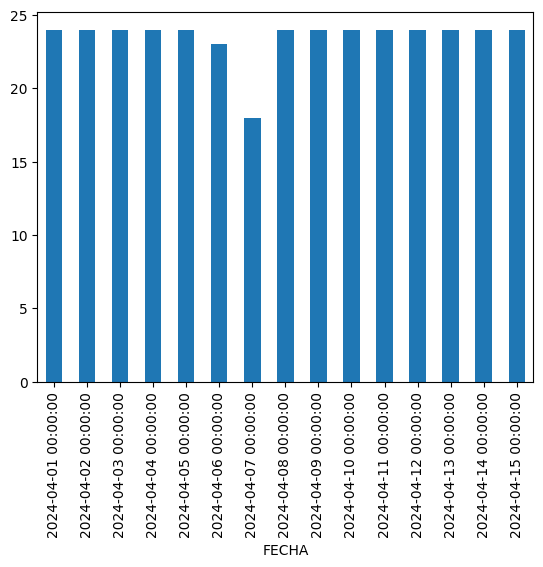

In [ ]:
df_filtered = RH[(RH['FECHA'] >= '2024-04-01') & (RH['FECHA'] <= '2024-04-15')]
df_filtered.groupby('FECHA').size().plot(kind='bar')

In [ ]:
fechas.info()

<class 'pandas.core.series.Series'>
DatetimeIndex: 366 entries, 2024-01-01 to 2024-12-31
Series name: count
Non-Null Count  Dtype
--------------  -----
366 non-null    int64
dtypes: int64(1)
memory usage: 5.7 KB


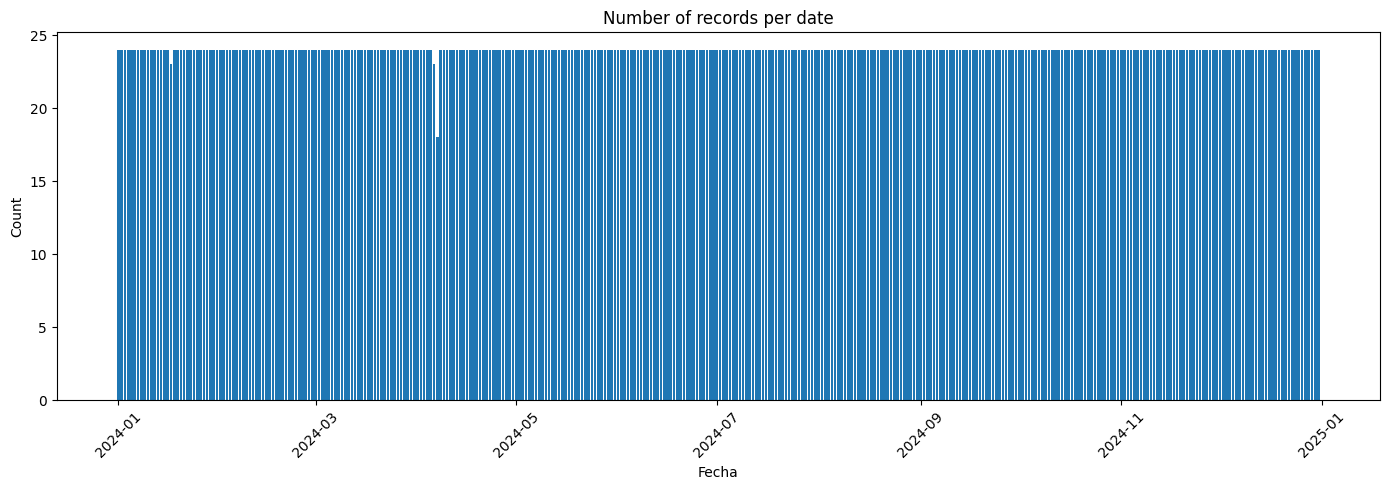

In [ ]:
fechas2 = CO['FECHA'].value_counts().sort_index()

plt.figure(figsize=(14, 5))
plt.bar(fechas.index, fechas.values)

plt.xlabel('Fecha')
plt.ylabel('Count')
plt.title('Number of records per date')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
fechas2.info()

<class 'pandas.core.series.Series'>
DatetimeIndex: 366 entries, 2024-01-01 to 2024-12-31
Series name: count
Non-Null Count  Dtype
--------------  -----
366 non-null    int64
dtypes: int64(1)
memory usage: 5.7 KB


In [ ]:
green_coverage = pd.read_csv('/content/drive/MyDrive/Big Data/green_space_features_wide_final.csv')
green_coverage = green_coverage.replace(-99, np.nan) # Assuming -99 represents null values, similar to other dataframes
green_coverage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   station_id                  28 non-null     object 
 1   n_green_patches_500m        28 non-null     int64  
 2   n_green_patches_1000m       28 non-null     int64  
 3   n_green_patches_2000m       28 non-null     int64  
 4   green_area_m2_500m          28 non-null     float64
 5   green_area_m2_1000m         28 non-null     float64
 6   green_area_m2_2000m         28 non-null     float64
 7   green_cover_pct_500m        28 non-null     float64
 8   green_cover_pct_1000m       28 non-null     float64
 9   green_cover_pct_2000m       28 non-null     float64
 10  mean_patch_area_m2_500m     28 non-null     float64
 11  mean_patch_area_m2_1000m    28 non-null     float64
 12  mean_patch_area_m2_2000m    28 non-null     float64
 13  dist_nearest_green_m_500m   18 non-nu

In [ ]:
temp_long.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 245728 entries, 0 to 245727
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   FECHA        245728 non-null  datetime64[ns]
 1   HORA         245728 non-null  int64         
 2   STATION      245728 non-null  object        
 3   temperature  125319 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 7.5+ MB


In [ ]:
rh_long.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 245728 entries, 0 to 245727
Data columns (total 4 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   FECHA              245728 non-null  datetime64[ns]
 1   HORA               245728 non-null  int64         
 2   STATION            245728 non-null  object        
 3   relative humidity  153881 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 7.5+ MB


In [ ]:
ws_long.info

<bound method DataFrame.info of             FECHA  HORA STATION  wind speed
0      2024-01-01     1     ACO         NaN
1      2024-01-01     2     ACO         NaN
2      2024-01-01     3     ACO         NaN
3      2024-01-01     4     ACO         NaN
4      2024-01-01     5     ACO         NaN
...           ...   ...     ...         ...
245723 2024-12-31    20     XAL         NaN
245724 2024-12-31    21     XAL         NaN
245725 2024-12-31    22     XAL         NaN
245726 2024-12-31    23     XAL         NaN
245727 2024-12-31    24     XAL         NaN

[245728 rows x 4 columns]>

In [ ]:
wd_long.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 245728 entries, 0 to 245727
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   FECHA           245728 non-null  datetime64[ns]
 1   HORA            245728 non-null  int64         
 2   STATION         245728 non-null  object        
 3   wind direction  142709 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 7.5+ MB


In [ ]:
CO_long.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 289806 entries, 0 to 289805
Data columns (total 4 columns):
 #   Column   Non-Null Count   Dtype         
---  ------   --------------   -----         
 0   FECHA    289806 non-null  datetime64[ns]
 1   HORA     289806 non-null  int64         
 2   STATION  289806 non-null  object        
 3   CO       183907 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 8.8+ MB


In [ ]:
print(merged_meteorological.head(15))

        FECHA  HORA STATION  temperature  relative humidity  wind speed  \
0  2024-01-01     1     ACO          NaN                -99         NaN   
1  2024-01-01     1     AJM          6.0                 57         3.5   
2  2024-01-01     1     AJU          1.0                 99         0.9   
3  2024-01-01     1     BJU         12.0                 56         0.8   
4  2024-01-01     1     CHO          NaN                -99         NaN   
5  2024-01-01     1     CUA         11.0                 52         0.9   
6  2024-01-01     1     CUT          8.0                 58         0.9   
7  2024-01-01     1     FAC          8.0                 59         0.5   
8  2024-01-01     1     FAR          NaN                 60         NaN   
9  2024-01-01     1     GAM          NaN                -99         NaN   
10 2024-01-01     1     HGM          NaN                -99         NaN   
11 2024-01-01     1     INN          7.0                 78         1.3   
12 2024-01-01     1     L

In [ ]:
df_pollulants_meteorological['STATION'].nunique()

37

In [ ]:
df_pollulants_meteorological.head(10)

,FECHA,HORA,STATION,temperature,relative humidity,wind speed,wind direction,CO,NO,NO2,NOx,03,PM10,PM25,PMCO,SO2
0,2024-01-01,1,ACO,NaN,-99.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-01-01,1,AJM,6.0,57.0,3.5,320.0,0.23,0.0,10.0,10.0,11.0,44.0,33.0,11.0,5.0
2,2024-01-01,1,AJU,1.0,99.0,0.9,54.0,NaN,NaN,NaN,NaN,43.0,NaN,NaN,NaN,NaN
3,2024-01-01,1,ATI,NaN,NaN,NaN,NaN,0.31,1.0,13.0,14.0,20.0,36.0,NaN,NaN,5.0
4,2024-01-01,1,BJU,12.0,56.0,0.8,173.0,1.18,NaN,43.0,NaN,3.0,62.0,42.0,20.0,NaN
5,2024-01-01,1,CAM,NaN,NaN,NaN,NaN,1.15,4.0,41.0,45.0,5.0,67.0,46.0,21.0,7.0
6,2024-01-01,1,CCA,NaN,NaN,NaN,NaN,0.88,7.0,31.0,38.0,9.0,NaN,NaN,NaN,3.0
7,2024-01-01,1,CHO,NaN,-99.0,NaN,NaN,0.59,3.0,14.0,17.0,29.0,NaN,NaN,NaN,4.0
8,2024-01-01,1,COY,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,2024-01-01,1,CUA,11.0,52.0,0.9,286.0,0.48,3.0,15.0,17.0,38.0,NaN,NaN,NaN,10.0


In [ ]:
df_pollulants_meteorological.head(10)

,FECHA,HORA,STATION,temperature,relative humidity,wind speed,wind direction,CO,NO,NO2,NOx,03,PM10,PM25,PMCO,SO2
1,2024-01-01,1,AJM,6.0,57.0,3.5,320.0,0.23,0.0,10.0,10.0,11.0,44.0,33.0,11.0,5.0
2,2024-01-01,1,AJU,1.0,99.0,0.9,54.0,NaN,NaN,NaN,NaN,43.0,NaN,NaN,NaN,NaN
4,2024-01-01,1,BJU,12.0,56.0,0.8,173.0,1.18,NaN,43.0,NaN,3.0,62.0,42.0,20.0,NaN
5,2024-01-01,1,CAM,NaN,NaN,NaN,NaN,1.15,4.0,41.0,45.0,5.0,67.0,46.0,21.0,7.0
6,2024-01-01,1,CCA,NaN,NaN,NaN,NaN,0.88,7.0,31.0,38.0,9.0,NaN,NaN,NaN,3.0
8,2024-01-01,1,COY,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,2024-01-01,1,CUA,11.0,52.0,0.9,286.0,0.48,3.0,15.0,17.0,38.0,NaN,NaN,NaN,10.0
13,2024-01-01,1,GAM,NaN,-99.0,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN
14,2024-01-01,1,HGM,NaN,-99.0,NaN,NaN,NaN,18.0,44.0,62.0,NaN,NaN,NaN,NaN,4.0
16,2024-01-01,1,IZT,NaN,NaN,NaN,NaN,1.38,14.0,45.0,59.0,NaN,117.0,NaN,NaN,3.0


In [ ]:
df_pollulants_meteorological['STATION'].nunique()

21

Uploading population density dataset, from the census made in 2020 https://www.inegi.org.mx/programas/ccpv/2020/#datos_abiertos


In [ ]:
pop_density = pd.read_csv('/content/drive/MyDrive/Big Data/pop_density.csv')

In [ ]:
pop_density.head()

,ENTIDAD,NOM_ENT,MUN,NOM_MUN,LOC,NOM_LOC,LONGITUD,LATITUD,ALTITUD,POBTOT,...,VPH_CEL,VPH_INTER,VPH_STVP,VPH_SPMVPI,VPH_CVJ,VPH_SINRTV,VPH_SINLTC,VPH_SINCINT,VPH_SINTIC,TAMLOC
0,9,Ciudad de México,0,Total de la entidad Ciudad de México,0,Total de la Entidad,NaN,NaN,NaN,9209944,...,2536523,2084156,1290811,957162,568827,46172,77272,561128,10528,*
1,9,Ciudad de México,0,Total de la entidad Ciudad de México,9998,Localidades de una vivienda,NaN,NaN,NaN,320,...,67,23,17,8,8,9,14,52,5,*
2,9,Ciudad de México,0,Total de la entidad Ciudad de México,9999,Localidades de dos viviendas,NaN,NaN,NaN,364,...,89,27,22,6,4,10,15,72,3,*
3,9,Ciudad de México,2,Azcapotzalco,0,Total del Municipio,NaN,NaN,NaN,432205,...,123961,105899,66399,50965,31801,1661,2869,22687,322,*
4,9,Ciudad de México,2,Azcapotzalco,1,Azcapotzalco,"99°11'03.698"" W","19°29'02.770"" N",2244.0,432205,...,123961,105899,66399,50965,31801,1661,2869,22687,322,12


Cleaning data

In [ ]:
pop_density_mun = (
    pop_density[
        (pop_density["NOM_LOC"] == "Total del Municipio")
    ]
    [["NOM_MUN", "LOC", "NOM_LOC", "POBTOT"]]
)

pop_density_mun.head(17)
#16 minicipalitites in total

,NOM_MUN,LOC,NOM_LOC,POBTOT
3,Azcapotzalco,0,Total del Municipio,432205
5,Coyoacán,0,Total del Municipio,614447
7,Cuajimalpa de Morelos,0,Total del Municipio,217686
34,Gustavo A. Madero,0,Total del Municipio,1173351
36,Iztacalco,0,Total del Municipio,404695
38,Iztapalapa,0,Total del Municipio,1835486
40,La Magdalena Contreras,0,Total del Municipio,247622
66,Milpa Alta,0,Total del Municipio,152685
313,Álvaro Obregón,0,Total del Municipio,759137
322,Tláhuac,0,Total del Municipio,392313


In [ ]:
pop_density_mun['NOM_MUN'].unique()

array(['Azcapotzalco', 'Coyoacán', 'Cuajimalpa de Morelos',
       'Gustavo A. Madero', 'Iztacalco', 'Iztapalapa',
       'La Magdalena Contreras', 'Milpa Alta', 'Álvaro Obregón',
       'Tláhuac', 'Tlalpan', 'Xochimilco', 'Benito Juárez', 'Cuauhtémoc',
       'Miguel Hidalgo', 'Venustiano Carranza'], dtype=object)

Uploading stations dataset

In [ ]:
stations_pop = stations.merge(
    pop_density_mun,
    on="NOM_MUN",
    how="left"
)


stations_pop['STATION'].nunique()
stations_pop['NOM_MUN'].unique()

#28 stations distributed in 15 municipalities, tlahuac is missing (no stations registered there)

array(['Tlalpan', 'Benito Juárez', 'Azcapotzalco', 'Coyoacán',
       'Gustavo A. Madero', 'Xochimilco', 'Cuajimalpa de Morelos',
       'Cuauhtémoc', 'Iztacalco', 'Miguel Hidalgo', 'Venustiano Carranza',
       'Milpa Alta', 'Álvaro Obregón', 'La Magdalena Contreras',
       'Iztapalapa'], dtype=object)

In [ ]:
stations_pop.head(10)

,STATION,Nombre,NOM_MUN,NOM_ENT,LOC,NOM_LOC,POBTOT
0,AJU,Ajusco,Tlalpan,Ciudad de México,0,Total del Municipio,699928
1,AJM,Ajusco Medio,Tlalpan,Ciudad de México,0,Total del Municipio,699928
2,BJU,Benito Juarez,Benito Juárez,Ciudad de México,0,Total del Municipio,434153
3,CAM,Camarones,Azcapotzalco,Ciudad de México,0,Total del Municipio,432205
4,CCA,Centro de Ciencias de la Atmósfera,Coyoacán,Ciudad de México,0,Total del Municipio,614447
5,TEC,Cerro del Tepeyac,Gustavo A. Madero,Ciudad de México,0,Total del Municipio,1173351
6,COR,CORENA,Xochimilco,Ciudad de México,0,Total del Municipio,442178
7,CUA,Cuajimalpa,Cuajimalpa de Morelos,Ciudad de México,0,Total del Municipio,217686
8,DIC,Diconsa,Tlalpan,Ciudad de México,0,Total del Municipio,699928
9,EAJ,Ecoguardas Ajusco,Tlalpan,Ciudad de México,0,Total del Municipio,699928


In [ ]:
airquality_pop = df_pollulants_meteorological.merge(
    stations_pop[["STATION", "NOM_MUN", "POBTOT"]],
    on="STATION",
    how="left"
)

airquality_pop.head(10)

NameError: name 'stations_pop' is not defined

Merge stations_pop with df_meteorological_pollutant

In [ ]:
df_pollulants_meteorological['STATION'].nunique()

21

In [ ]:
airquality_pop['STATION'].nunique()

21

Adding the number of green spaces in a 500m distance and in a 1000m distance for trial


In [ ]:
green_spaces_df = pd.read_csv('/content/drive/MyDrive/Big Data/green_spaces_df.csv')
green_spaces_df.head(10)

,STATION,n_green_patches_500m,n_green_patches_1000m
0,AJM,1,9
1,AJU,0,1
2,BJU,13,32
3,CAM,6,31
4,CCA,48,140
5,COR,1,2
6,CUA,2,9
7,DIC,0,0
8,EAJ,0,0
9,EDL,0,0


In [ ]:
airquality_pop_green = airquality_pop.merge(
    green_spaces_df[["STATION", "n_green_patches_500m", "n_green_patches_1000m"]],
    on="STATION",
    how="left"
)

airquality_pop_green.head(10)
airquality_pop_green.info() #184416 entries

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 184416 entries, 0 to 184415
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   FECHA                  184416 non-null  datetime64[ns]
 1   HORA                   184416 non-null  int64         
 2   STATION                184416 non-null  object        
 3   temperature            74014 non-null   float64       
 4   relative humidity      140416 non-null  float64       
 5   wind speed             87698 non-null   float64       
 6   wind direction         87698 non-null   float64       
 7   CO                     98789 non-null   float64       
 8   NO                     89729 non-null   float64       
 9   NO2                    104850 non-null  float64       
 10  NOx                    89729 non-null   float64       
 11  03                     120749 non-null  float64       
 12  PM10                   69564 non-null   floa

In [ ]:
airquality_pop_green.isna().sum().sort_values(ascending=False)

,0
PMCO,128169
PM10,114852
temperature,110402
PM25,109552
wind direction,96718
wind speed,96718
NO,94687
NOx,94687
SO2,91561
CO,85627


In [ ]:
airquality_pop_green['STATION'].nunique()

21

In [ ]:
airquality_pop_green.groupby("STATION").size()

,0
STATION,
AJM,8782
AJU,8782
BJU,8782
CAM,8782
CCA,8782
COY,8782
CUA,8782
GAM,8782
HGM,8782


In [ ]:
n_missing = airquality_pop_green["03"].isna().sum()
n_total = len(airquality_pop_green)

print(f"Missing O3 values: {n_missing}")
print(f"Percentage missing: {100 * n_missing / n_total:.2f}%")

Missing O3 values: 63667
Percentage missing: 34.52%


In [ ]:
airquality_pop_green.groupby("STATION")["03"].apply(lambda x: x.isna().sum())

,03
STATION,
AJM,731
AJU,578
BJU,2421
CAM,2376
CCA,616
COY,8782
CUA,1109
GAM,3532
HGM,2107


In [ ]:
airquality_pop_green.groupby(airquality_pop_green["FECHA"].dt.month)["03"].apply(lambda x: x.isna().mean())

,03
FECHA,
1,0.310133
2,0.292214
3,0.285970
4,0.269396
5,0.318612
6,0.349471
7,0.350038
8,0.405082
9,0.471693


In [ ]:
airquality_pop_green = airquality_pop_green.dropna(subset=["03"])

In [ ]:
airquality_pop_green.info()

<class 'pandas.core.frame.DataFrame'>
Index: 120749 entries, 0 to 184415
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   FECHA                  120749 non-null  datetime64[ns]
 1   HORA                   120749 non-null  int64         
 2   STATION                120749 non-null  object        
 3   temperature            61969 non-null   float64       
 4   relative humidity      97942 non-null   float64       
 5   wind speed             68403 non-null   float64       
 6   wind direction         68403 non-null   float64       
 7   CO                     94409 non-null   float64       
 8   NO                     86925 non-null   float64       
 9   NO2                    98473 non-null   float64       
 10  NOx                    86925 non-null   float64       
 11  03                     120749 non-null  float64       
 12  PM10                   62774 non-null   float64  

Cleaning dataset

# Statistical analysis


In [ ]:
stations= pd.read_csv('/content/drive/MyDrive/Big Data/estaciones_cdmx.csv')
stations.head()

,STATION,Nombre,NOM_MUN,NOM_ENT,Latitud,Longitud
0,AJU,Ajusco,Tlalpan,Ciudad de México,"19,154286","-99,162611"
1,AJM,Ajusco Medio,Tlalpan,Ciudad de México,"19,272161","-99,207744"
2,BJU,Benito Juarez,Benito Juárez,Ciudad de México,"19,371675","-99,159074"
3,CAM,Camarones,Azcapotzalco,Ciudad de México,"19,468404","-99,169794"
4,CCA,Centro de Ciencias de la Atmósfera,Coyoacán,Ciudad de México,"19,326200","-99,1761"


In [ ]:
import folium

for col in ['Latitud', 'Longitud']:
    stations[col] = pd.to_numeric(
        stations[col].astype(str).str.replace(',', '.', regex=False)
    )

# Create a map centered on Mexico City
m = folium.Map(
    location=[stations['Latitud'].mean(), stations['Longitud'].mean()],
    zoom_start=11
)

# Add station markers
for _, row in stations.iterrows():
    folium.Marker(
        location=[row['Latitud'], row['Longitud']],
        popup=f"{row['Nombre']} ({row['STATION']})",
        tooltip=row['Nombre']
    ).add_to(m)

m = folium.Map(
    location=[stations['Latitud'].mean(), stations['Longitud'].mean()],
    zoom_start=11
)

for _, row in stations.iterrows():
    # The marker itself
    folium.CircleMarker(
        location=[row['Latitud'], row['Longitud']],
        radius=4,
        color='blue',
        fill=True,
        fill_opacity=0.7,
        popup=f"{row['Nombre']} ({row['STATION']})",
        tooltip=row['Nombre']
    ).add_to(m)

    # The permanent text label next to it
    folium.map.Marker(
        [row['Latitud'], row['Longitud']],
        icon=folium.DivIcon(
            icon_size=(150, 36),
            icon_anchor=(-5, 10),  # shifts the label to the right of the point
            html=f'<div style="font-size:9pt; color:black; white-space:nowrap;">{row["STATION"]}</div>'
        )
    ).add_to(m)
m

In [ ]:
airquality_pop_clean = airquality_pop.dropna()

In [ ]:
airquality_pop_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11475 entries, 1 to 324916
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   FECHA              11475 non-null  datetime64[ns]
 1   HORA               11475 non-null  int64         
 2   STATION            11475 non-null  object        
 3   temperature        11475 non-null  float64       
 4   relative humidity  11475 non-null  float64       
 5   wind speed         11475 non-null  float64       
 6   wind direction     11475 non-null  float64       
 7   CO                 11475 non-null  float64       
 8   NO                 11475 non-null  float64       
 9   NO2                11475 non-null  float64       
 10  NOx                11475 non-null  float64       
 11  03                 11475 non-null  float64       
 12  PM10               11475 non-null  float64       
 13  PM25               11475 non-null  float64       
 14  PMCO      

In [ ]:
airquality_pop_clean['STATION'].unique()

array(['AJM', 'MER', 'PED'], dtype=object)

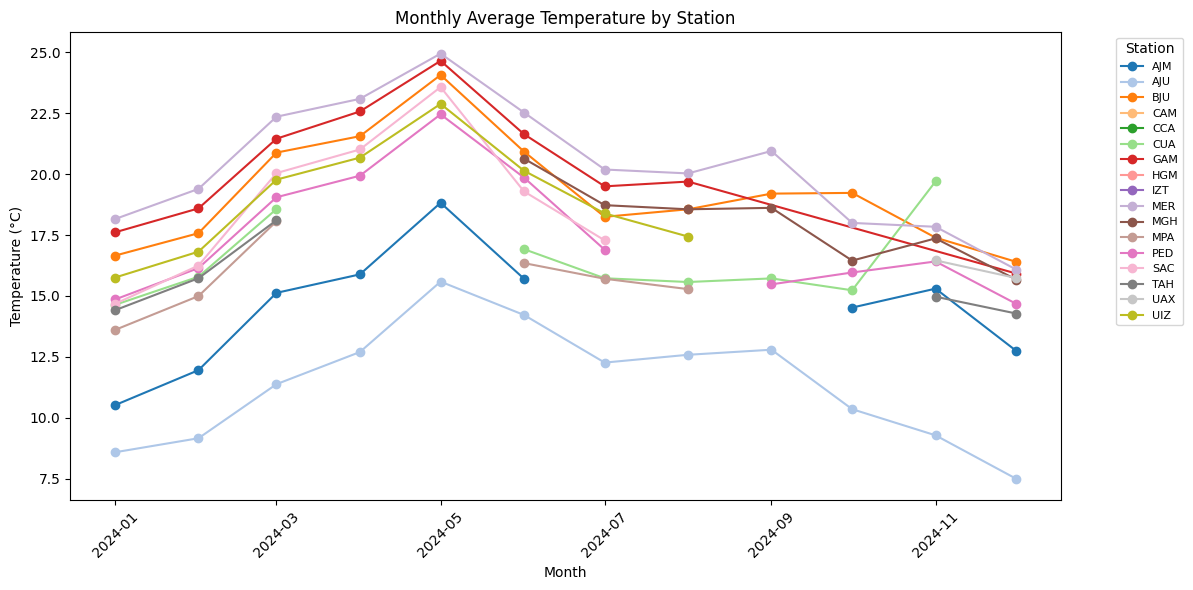

In [ ]:
# Monthly average temperature by station
monthly_station_avg = (
    airquality_pop.groupby(["STATION", "month"], as_index=False)["temperature"]
      .mean()
)


stations = monthly_station_avg["STATION"].unique()
# Convert Period to datetime for matplotlib
monthly_station_avg["month"] = monthly_station_avg["month"].dt.to_timestamp()


# Create a color map with one unique color per station
colors = plt.cm.tab20(range(len(stations)))

fig, ax = plt.subplots(figsize=(12, 6))

for station, color in zip(stations, colors):
    group = monthly_station_avg[monthly_station_avg["STATION"] == station]

    ax.plot(
        group["month"],
        group["temperature"],
        marker="o",
        linewidth=1.5,
        label=station,
        color=color
    )

ax.set_title("Monthly Average Temperature by Station")
ax.set_xlabel("Month")
ax.set_ylabel("Temperature (°C)")

plt.xticks(rotation=45)

ax.legend(
    title="Station",
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()
plt.show()


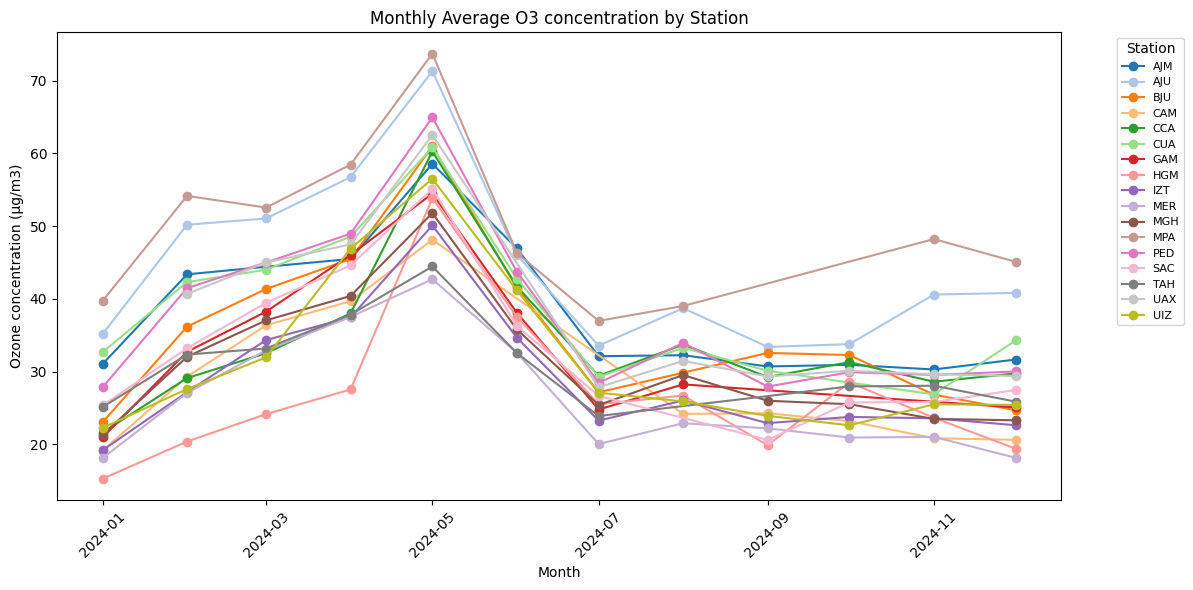

In [ ]:
# Monthly average O3 by station
monthly_station_avg_o3 = (
    airquality_pop.groupby(["STATION", "month"], as_index=False)["03"]
      .mean()
)
stations = monthly_station_avg["STATION"].unique()

# Convert Period to datetime for matplotlib
monthly_station_avg_o3["month"] = monthly_station_avg_o3["month"].dt.to_timestamp()


colors = plt.cm.tab20(range(len(stations)))

fig, ax = plt.subplots(figsize=(12, 6))

for station, color in zip(stations, colors):
    group = monthly_station_avg_o3[monthly_station_avg_o3["STATION"] == station]

    ax.plot(
        group["month"],
        group["03"],
        marker="o",
        linewidth=1.5,
        label=station,
        color=color
    )

ax.set_title("Monthly Average O3 concentration by Station")
ax.set_xlabel("Month")
ax.set_ylabel("Ozone concentration (µg/m3)")


plt.xticks(rotation=45)

ax.legend(
    title="Station",
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()
plt.show()

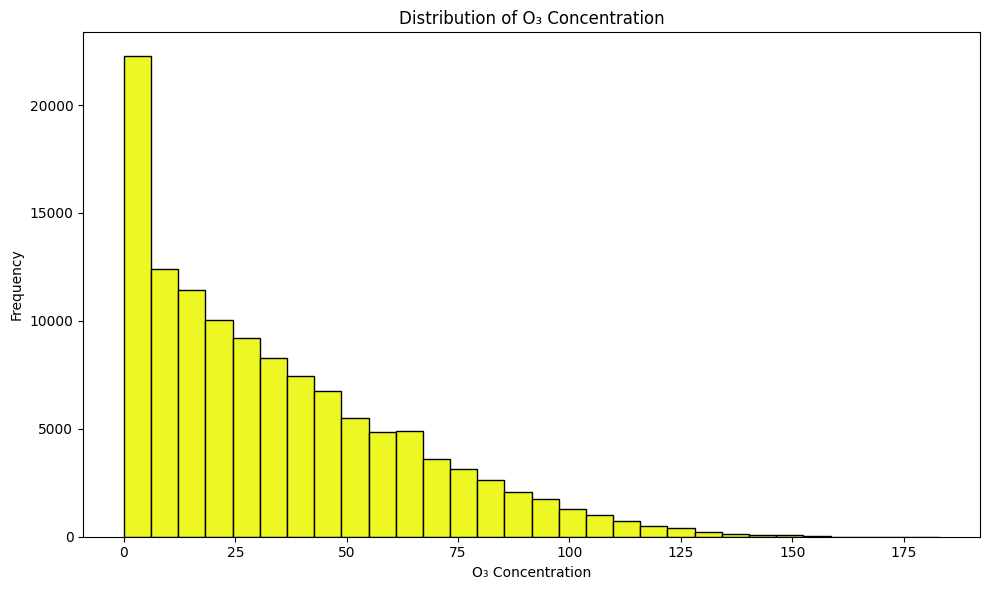

In [ ]:
plt.figure(figsize=(10, 6))

plt.hist(
    airquality_pop["03"].dropna(),
    bins=30,
    edgecolor="black",
    color="#ecf723"
)

plt.title("Distribution of O₃ Concentration")
plt.xlabel("O₃ Concentration")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

                     03  temperature  relative humidity  wind speed  \
03                 1.00         0.59              -0.54        0.38   
temperature        0.59         1.00              -0.64        0.27   
relative humidity -0.54        -0.64               1.00       -0.30   
wind speed         0.38         0.27              -0.30        1.00   
wind direction    -0.17        -0.02               0.03       -0.02   
CO                -0.34        -0.23               0.09       -0.39   
PM10               0.21         0.31              -0.36        0.02   
PM25               0.24         0.19              -0.17       -0.12   
SO2               -0.08        -0.07              -0.00       -0.10   
NO                -0.36        -0.24               0.13       -0.33   
NOx               -0.41        -0.21               0.10       -0.40   
NO2               -0.38        -0.14               0.04       -0.42   
PMCO               0.13         0.31              -0.43        0.10   

     

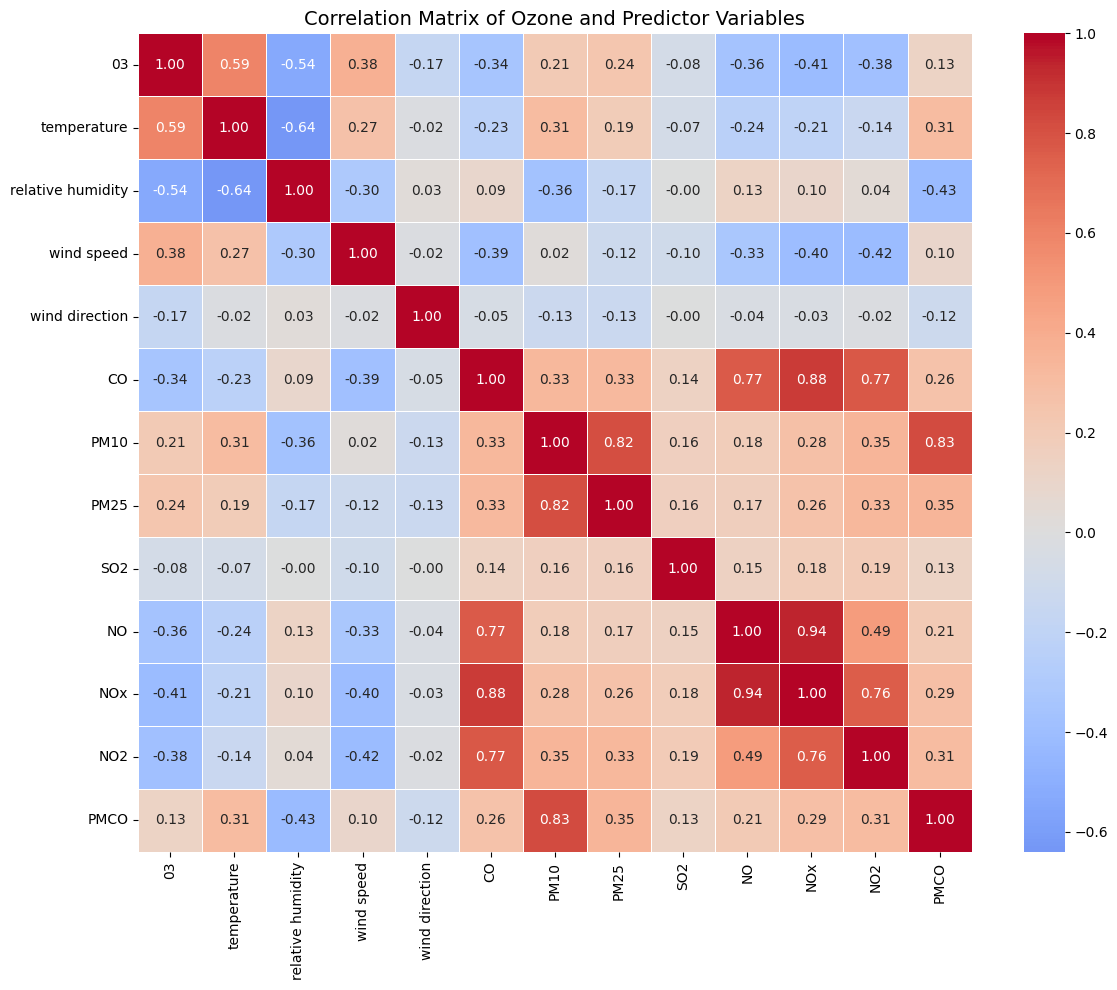

In [ ]:
feature_vars = ['03','temperature', 'relative humidity', 'wind speed', 'wind direction', 'CO', 'PM10', 'PM25', 'SO2', 'NO', 'NOx', 'NO2', 'PMCO']
corr_matrix = airquality_pop[feature_vars].corr()


# Display matrix

print(corr_matrix.round(2))


# Plot heatmap

plt.figure(figsize=(12,10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title(
    "Correlation Matrix of Ozone and Predictor Variables",
    fontsize=14
)

plt.tight_layout()

plt.show()

#OLS

In [ ]:
airquality_pop.isnull().sum()

,0
FECHA,0
HORA,0
STATION,0
temperature,58780
relative humidity,49129
wind speed,52346
wind direction,52346
CO,26340
NO,33824
NO2,22276


In [ ]:
# Calculate missing values
missing_table = pd.DataFrame({
    "Missing Values": airquality_pop.isnull().sum(),
    "Percentage (%)": (airquality_pop.isnull().mean() * 100).round(2)
})



# Sort by percentage of missing values
missing_table = missing_table.sort_values("Percentage (%)", ascending=False)

print(missing_table)

                   Missing Values  Percentage (%)
PMCO                        70362           58.27
temperature                 58780           48.68
PM10                        57975           48.01
PM25                        53417           44.24
wind direction              52346           43.35
wind speed                  52346           43.35
relative humidity           49129           40.69
NOx                         33824           28.01
NO                          33824           28.01
SO2                         32084           26.57
CO                          26340           21.81
NO2                         22276           18.45
FECHA                           0            0.00
STATION                         0            0.00
HORA                            0            0.00
03                              0            0.00
month                           0            0.00


In [ ]:
airquality_pop_nonan = airquality_pop.dropna()

In [ ]:
airquality_pop_nonan.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11475 entries, 1 to 324916
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   FECHA              11475 non-null  datetime64[ns]
 1   HORA               11475 non-null  int64         
 2   STATION            11475 non-null  object        
 3   temperature        11475 non-null  float64       
 4   relative humidity  11475 non-null  float64       
 5   wind speed         11475 non-null  float64       
 6   wind direction     11475 non-null  float64       
 7   CO                 11475 non-null  float64       
 8   NO                 11475 non-null  float64       
 9   NO2                11475 non-null  float64       
 10  NOx                11475 non-null  float64       
 11  03                 11475 non-null  float64       
 12  PM10               11475 non-null  float64       
 13  PM25               11475 non-null  float64       
 14  PMCO      

In [ ]:
airquality_pop_nonan['STATION'].unique()

array(['AJM', 'MER', 'PED'], dtype=object)

In [ ]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

df_ols = airquality_pop_nonan[predictors + [target]].copy()
X = df_ols[predictors]
y = df_ols[target]
X_ols = sm.add_constant(X)

# Fit OLS model

ols_model = sm.OLS(
    y,
    X_ols
).fit()


print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                     03   R-squared:                       0.697
Model:                            OLS   Adj. R-squared:                  0.696
Method:                 Least Squares   F-statistic:                     2194.
Date:                Sun, 12 Jul 2026   Prob (F-statistic):               0.00
Time:                        18:25:34   Log-Likelihood:                -48527.
No. Observations:               11475   AIC:                         9.708e+04
Df Residuals:                   11462   BIC:                         9.718e+04
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                30.8167      1.07

#More statistics

-> Relative humidity

In [ ]:
print(df_pollulants_meteorological["relative humidity"].isna().sum())

97038


/tmp/ipykernel_7267/762957371.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean_rh["FECHA"] = pd.to_datetime(df_clean_rh["FECHA"], errors="coerce")
/tmp/ipykernel_7267/762957371.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean_rh["month"] = df_clean_rh["FECHA"].dt.to_period("M")


   month_str  temperature
0    2024-01    14.347809
1    2024-02    15.594587
2    2024-03    18.637390
3    2024-04    19.642760
4    2024-05    22.034422
5    2024-06    18.903807
6    2024-07    17.202050
7    2024-08    17.109213
8    2024-09    17.080681
9    2024-10    15.447456
10   2024-11    16.050634
11   2024-12    14.059384


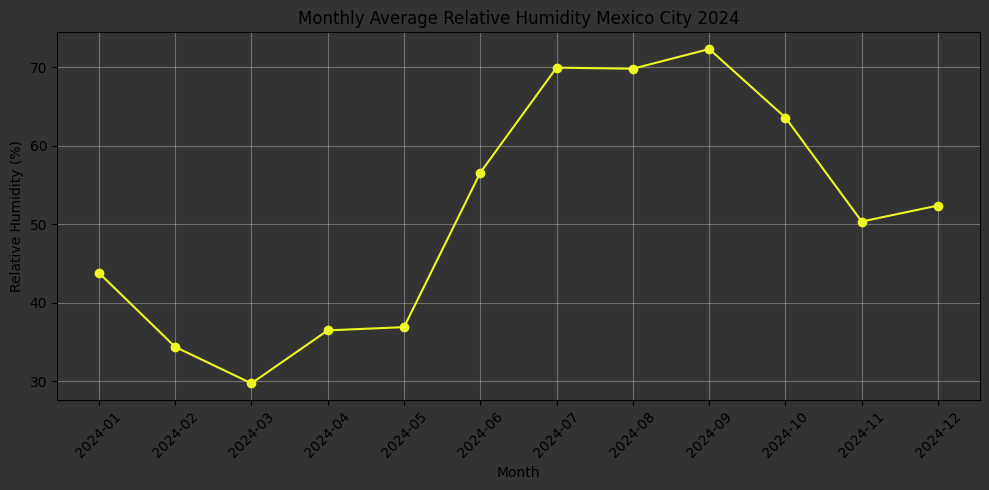

In [ ]:
df_clean_rh = df_pollulants_meteorological.dropna(subset=["relative humidity"])
df_clean_rh["FECHA"] = pd.to_datetime(df_clean_rh["FECHA"], errors="coerce")
df_clean_rh["month"] = df_clean_rh["FECHA"].dt.to_period("M")
monthly_avg_rh = (
    df_clean_rh.groupby("month")["relative humidity"]
    .mean()
    .reset_index()
)
monthly_avg_rh["month_str"] = monthly_avg["month"].dt.strftime("%Y-%m")
fig, ax = plt.subplots(figsize=(10, 5))

# Grey background (figure + plot area)
fig.patch.set_facecolor("#333333")
ax.set_facecolor("#333333")

ax.plot(monthly_avg["month_str"], monthly_avg_rh["relative humidity"], marker="o", color="#ecf723")
ax.set_title("Monthly Average Relative Humidity Mexico City 2024")
ax.set_xlabel("Month")
ax.set_ylabel("Relative Humidity (%)")
plt.xticks(rotation=45)
ax.grid(alpha=0.3, color="white")
plt.tight_layout()

plt.savefig(r"/content/sample_data/monthly_avg_rh2.png")
print(monthly_avg[["month_str", "temperature"]])

plt.show()


In [ ]:
print(df_pollulants_meteorological["wind speed"].isna().sum())

96718


/tmp/ipykernel_7267/1321837497.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean_ws["FECHA"] = pd.to_datetime(df_clean_ws["FECHA"], errors="coerce")
/tmp/ipykernel_7267/1321837497.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean_ws["month"] = df_clean_ws["FECHA"].dt.to_period("M")


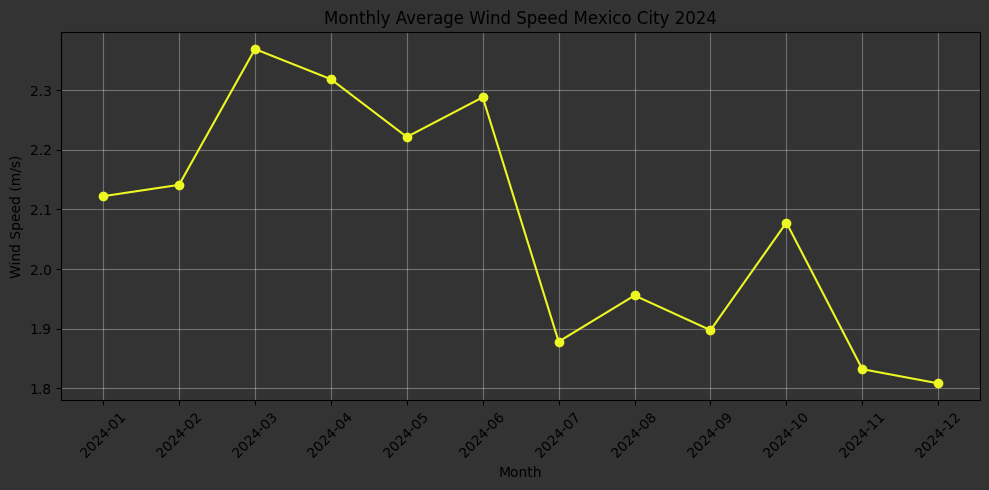

In [ ]:
df_clean_ws = df_pollulants_meteorological.dropna(subset=["wind speed"])
df_clean_ws["FECHA"] = pd.to_datetime(df_clean_ws["FECHA"], errors="coerce")
df_clean_ws["month"] = df_clean_ws["FECHA"].dt.to_period("M")
monthly_avg_ws= (
    df_clean_ws.groupby("month")["wind speed"]
    .mean()
    .reset_index()
)
monthly_avg_ws["month_str"] = monthly_avg["month"].dt.strftime("%Y-%m")
fig, ax = plt.subplots(figsize=(10, 5))

# Grey background (figure + plot area)
fig.patch.set_facecolor("#333333")
ax.set_facecolor("#333333")

#ax.bar(monthly_avg_ws["month_str"], monthly_avg_ws["wind speed"], color="#ecf723")
ax.plot(monthly_avg["month_str"], monthly_avg_ws["wind speed"], marker="o", color="#ecf723")
ax.set_title("Monthly Average Wind Speed Mexico City 2024")
ax.set_xlabel("Month")
ax.set_ylabel("Wind Speed (m/s)")
plt.xticks(rotation=45)
ax.grid(alpha=0.3, color="white")
plt.tight_layout()

plt.savefig(r"/content/sample_data/monthly_avg_ws2.png")
plt.show()

-> O3

In [ ]:
print(df_pollulants_meteorological["03"].isna().sum())

63667


/tmp/ipykernel_7267/2490471133.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean_CO["FECHA"] = pd.to_datetime(df_clean_CO["FECHA"], errors="coerce")
/tmp/ipykernel_7267/2490471133.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean_CO["month"] = df_clean_CO["FECHA"].dt.to_period("M")


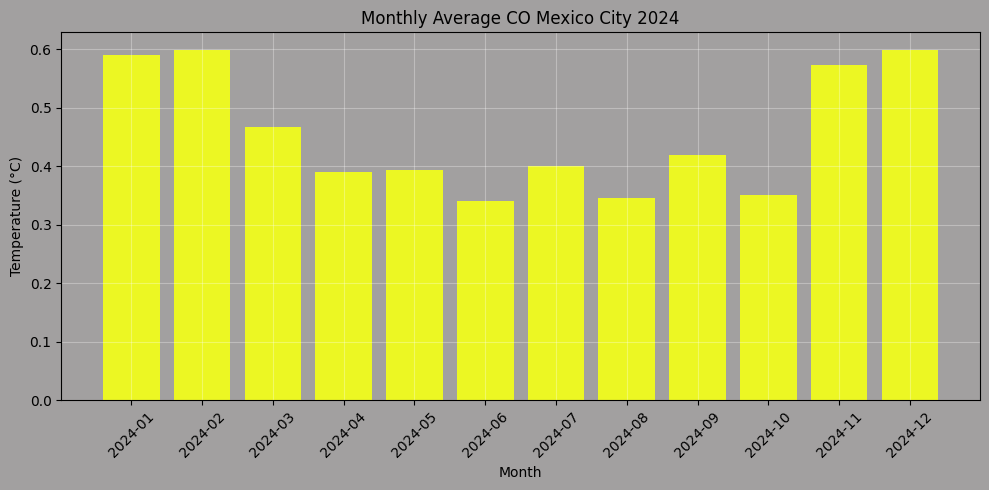

In [ ]:
df_clean_CO = df_pollulants_meteorological.dropna(subset=["CO"])
df_clean_CO["FECHA"] = pd.to_datetime(df_clean_CO["FECHA"], errors="coerce")
df_clean_CO["month"] = df_clean_CO["FECHA"].dt.to_period("M")
monthly_avg_CO= (
    df_clean_CO.groupby("month")["CO"]
    .mean()
    .reset_index()
)
monthly_avg_CO["month_str"] = monthly_avg["month"].dt.strftime("%Y-%m")
fig, ax = plt.subplots(figsize=(10, 5))

# Grey background (figure + plot area)
fig.patch.set_facecolor("#a2a0a0")
ax.set_facecolor("#a2a0a0")

ax.bar(monthly_avg_CO["month_str"], monthly_avg_CO["CO"], color="#ecf723")
#ax.plot(monthly_avg["month_str"], monthly_avg_ws["wind speed"], marker="o", color="#ecf723")
ax.set_title("Monthly Average CO Mexico City 2024")
ax.set_xlabel("Month")
ax.set_ylabel("Temperature (°C)")
plt.xticks(rotation=45)
ax.grid(alpha=0.3, color="white")
plt.tight_layout()

plt.savefig(r"/content/sample_data/monthly_avg_o3.png")
plt.show()

In [ ]:
#defining a function for ploting monthly averages
def plot_monthly_average(
    df,
    column,
    date_col="FECHA",
    title=None,
    ylabel=None,
    save_path=None,
    bar_color="#ecf723",
    bg_color="#a2a0a0",
    figsize=(10, 5)
):
    """
    Plot monthly average of a selected column.

    Parameters:
    ----------
    df : DataFrame
        Input dataframe
    column : str
        Column to calculate monthly average
    date_col : str
        Date column
    title : str
        Plot title
    ylabel : str
        Y-axis label
    save_path : str
        Optional file path to save figure
    """

    # Clean data
    df_clean = df.dropna(subset=[column]).copy()

    # Convert dates
    df_clean[date_col] = pd.to_datetime(
        df_clean[date_col],
        errors="coerce"
    )

    # Extract month
    df_clean["month"] = df_clean[date_col].dt.to_period("M")

    # Monthly average
    monthly_avg = (
        df_clean.groupby("month")[column]
        .mean()
        .reset_index()
    )

    monthly_avg["month_str"] = (
        monthly_avg["month"]
        .dt.strftime("%Y-%m")
    )

    # Plot
    fig, ax = plt.subplots(figsize=figsize)

    fig.patch.set_facecolor(bg_color)
    ax.set_facecolor(bg_color)

    ax.bar(
        monthly_avg["month_str"],
        monthly_avg[column],
        color=bar_color
    )

    ax.set_title(
        title if title else f"Monthly Average {column}"
    )
    ax.set_xlabel("Month")
    ax.set_ylabel(
        ylabel if ylabel else column
    )

    plt.xticks(rotation=45)
    ax.grid(alpha=0.3, color="white")
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path)

    plt.show()

    return monthly_avg

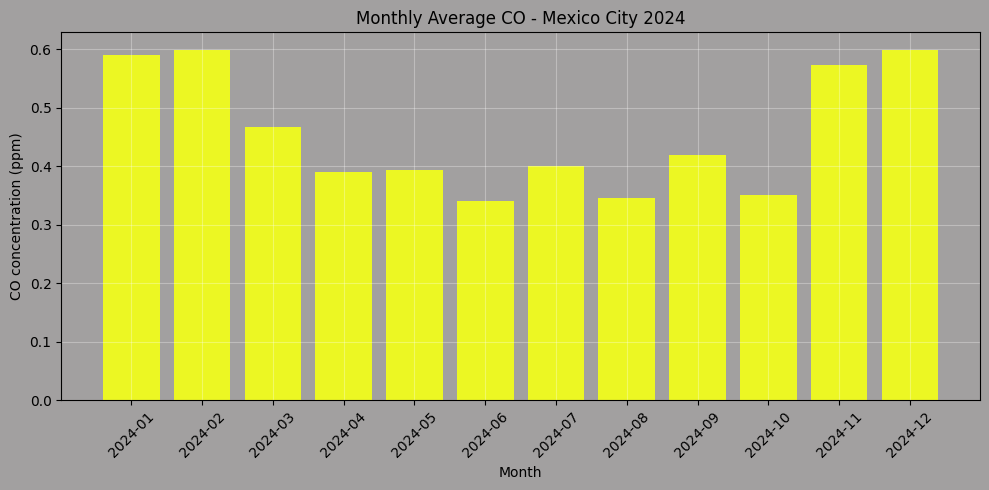

In [ ]:
monthly_avg_CO = plot_monthly_average(
    df_pollulants_meteorological,
    column="CO",
    title="Monthly Average CO - Mexico City 2024",
    ylabel="CO concentration (ppm)",
    save_path="/content/sample_data/monthly_avg_CO.png"
)

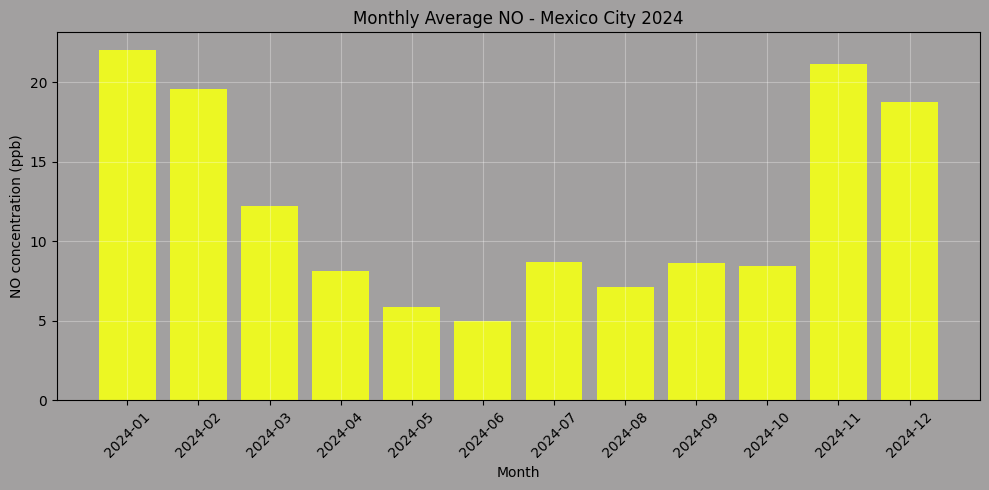

In [ ]:
monthly_avg_NO = plot_monthly_average(
    df_pollulants_meteorological,
    column="NO",
    title="Monthly Average NO - Mexico City 2024",
    ylabel="NO concentration (ppb)",
    save_path="/content/sample_data/monthly_avg_NO.png"
)

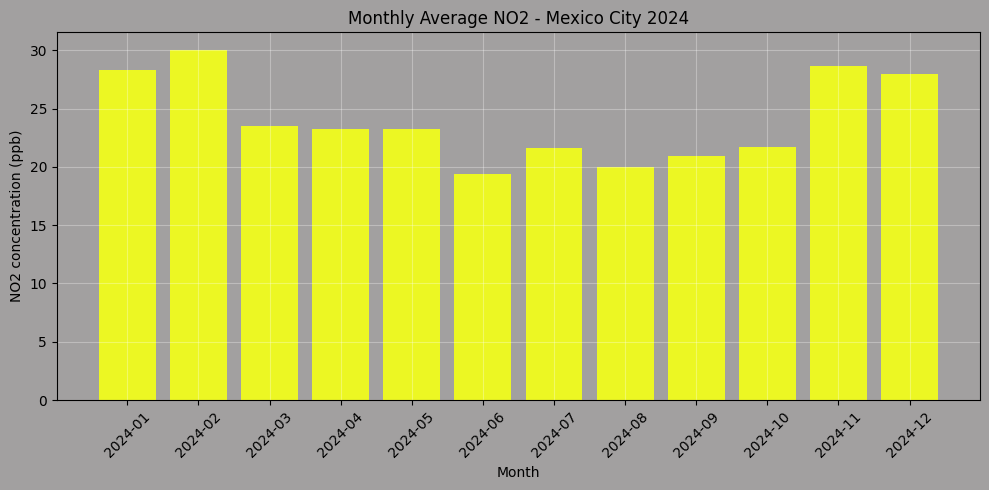

In [ ]:
monthly_avg_NO2 = plot_monthly_average(
    df_pollulants_meteorological,
    column="NO2",
    title="Monthly Average NO2 - Mexico City 2024",
    ylabel="NO2 concentration (ppb)",
    save_path="/content/sample_data/monthly_avg_NO2.png"
)

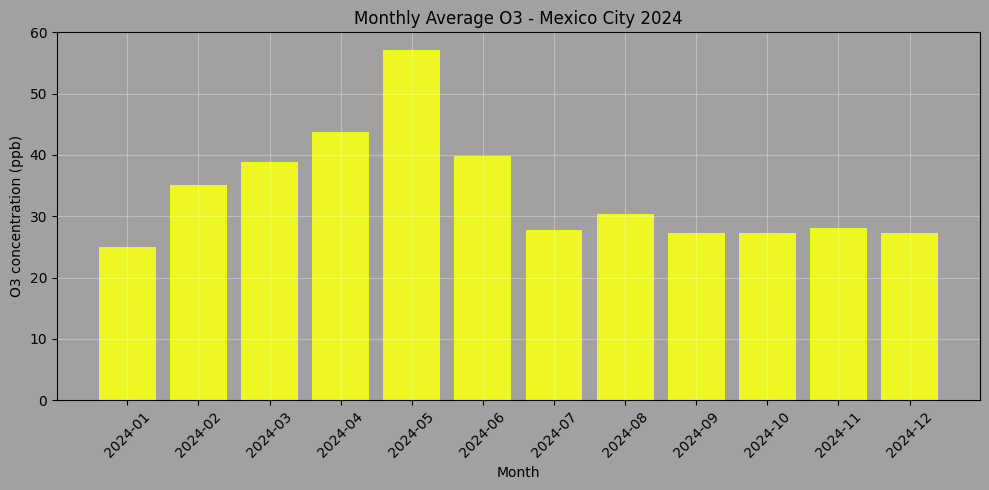

In [ ]:
monthly_avg_03 = plot_monthly_average(
    df_pollulants_meteorological,
    column="03",
    title="Monthly Average O3 - Mexico City 2024",
    ylabel="O3 concentration (ppb)",
    save_path="/content/sample_data/monthly_avg_O3.png"
)

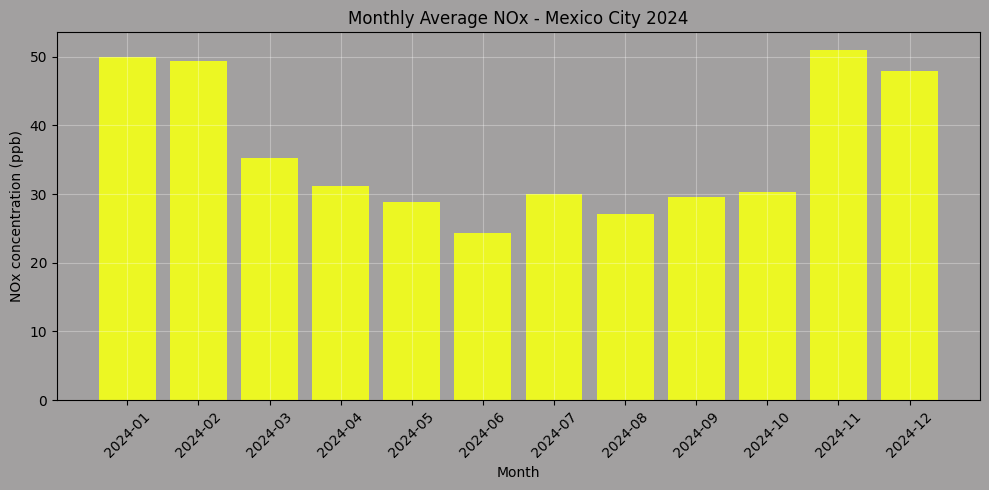

In [ ]:
monthly_avg_nox = plot_monthly_average(
    df_pollulants_meteorological,
    column="NOx",
    title="Monthly Average NOx - Mexico City 2024",
    ylabel="NOx concentration (ppb)",
    save_path="/content/sample_data/monthly_avg_NOx.png"
)

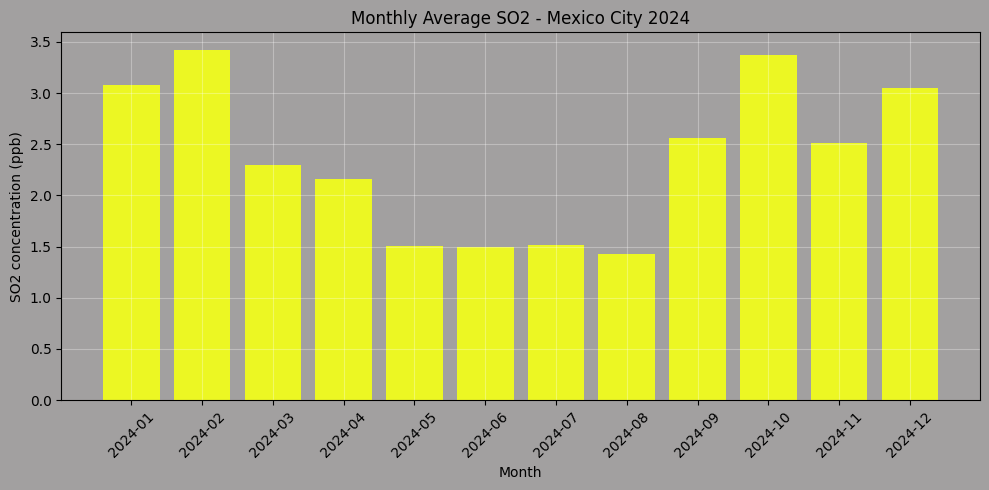

In [ ]:
monthly_avg_nox = plot_monthly_average(
    df_pollulants_meteorological,
    column="SO2",
    title="Monthly Average SO2 - Mexico City 2024",
    ylabel="SO2 concentration (ppb)",
    save_path="/content/sample_data/monthly_avg_SO2.png"
)

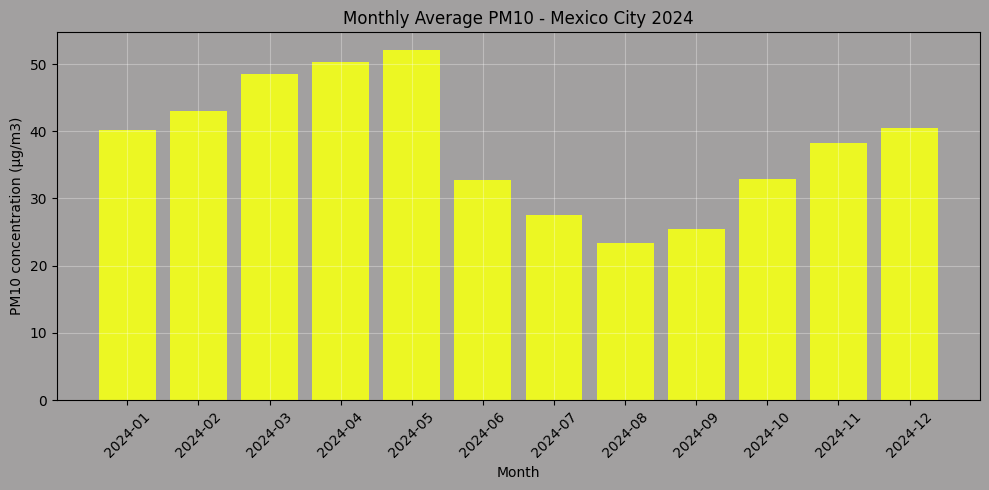

In [ ]:
monthly_avg_PM10 = plot_monthly_average(
    df_pollulants_meteorological,
    column="PM10",
    title="Monthly Average PM10 - Mexico City 2024",
    ylabel="PM10 concentration (µg/m3)",
    save_path="/content/sample_data/monthly_avg_PM10.png"
)

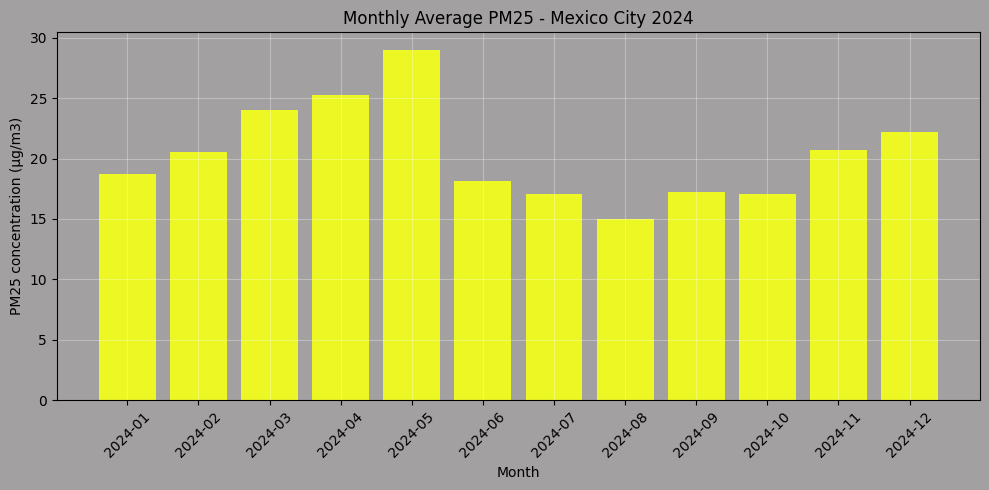

In [ ]:
monthly_avg_PM25 = plot_monthly_average(
    df_pollulants_meteorological,
    column="PM25",
    title="Monthly Average PM25 - Mexico City 2024",
    ylabel="PM25 concentration (µg/m3)",
    save_path="/content/sample_data/monthly_avg_PM25.png"
)

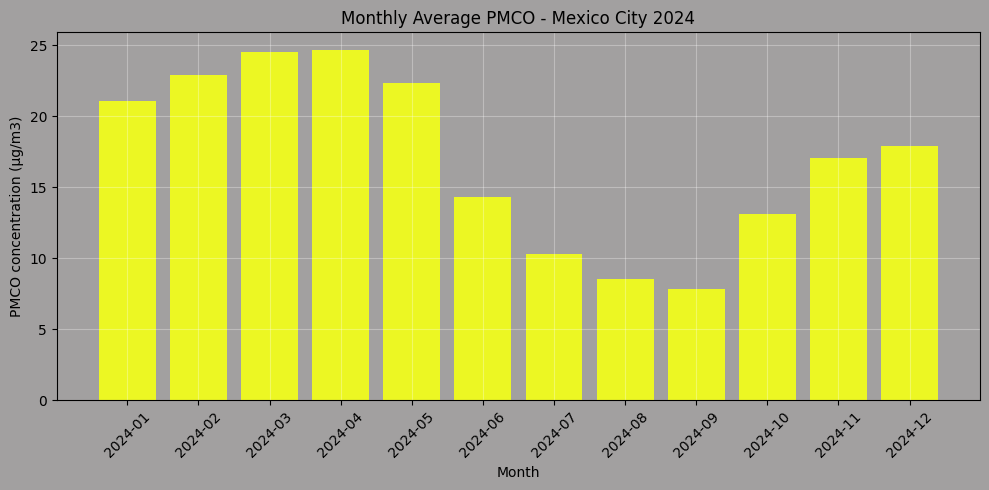

In [ ]:
monthly_avg_PMCO = plot_monthly_average(
    df_pollulants_meteorological,
    column="PMCO",
    title="Monthly Average PMCO - Mexico City 2024",
    ylabel="PMCO concentration (µg/m3)",
    save_path="/content/sample_data/monthly_avg_PMCO.png"
)

#Scatter Plots


In [ ]:
Cl_whole_poll = df_pollulants_meteorological.drop(columns=["STATION"]).dropna().drop(columns=["NOx"]).drop(columns=["NO"]).drop(columns=["PMCO"]).drop(columns=["NO2"]).drop(columns=["SO2"])

Cl_whole_poll

,FECHA,HORA,temperature,relative humidity,wind speed,wind direction,CO,03,PM10,PM25
1,2024-01-01,1,6.0,57.0,3.5,320.0,0.23,11.0,44.0,33.0
20,2024-01-01,1,14.0,56.0,0.7,304.0,1.24,3.0,73.0,52.0
57,2024-01-01,2,13.0,59.0,0.5,73.0,1.38,3.0,101.0,77.0
75,2024-01-01,3,4.0,63.0,3.9,314.0,0.22,17.0,24.0,18.0
112,2024-01-01,4,4.0,64.0,3.7,320.0,0.20,14.0,24.0,17.0
...,...,...,...,...,...,...,...,...,...,...
324842,2024-12-31,22,14.5,31.0,2.2,258.0,0.91,16.0,47.0,22.0
324855,2024-12-31,23,10.6,35.0,3.7,245.0,0.45,18.0,50.0,29.0
324879,2024-12-31,23,13.4,33.0,1.9,231.0,0.68,19.0,63.0,41.0
324892,2024-12-31,24,10.2,34.0,3.3,242.0,0.35,22.0,37.0,22.0


In [ ]:
Cl_whole_poll2 = df_pollulants_meteorological.dropna()

Cl_whole_poll2['STATION'].unique()

array(['AJM', 'MER', 'PED'], dtype=object)

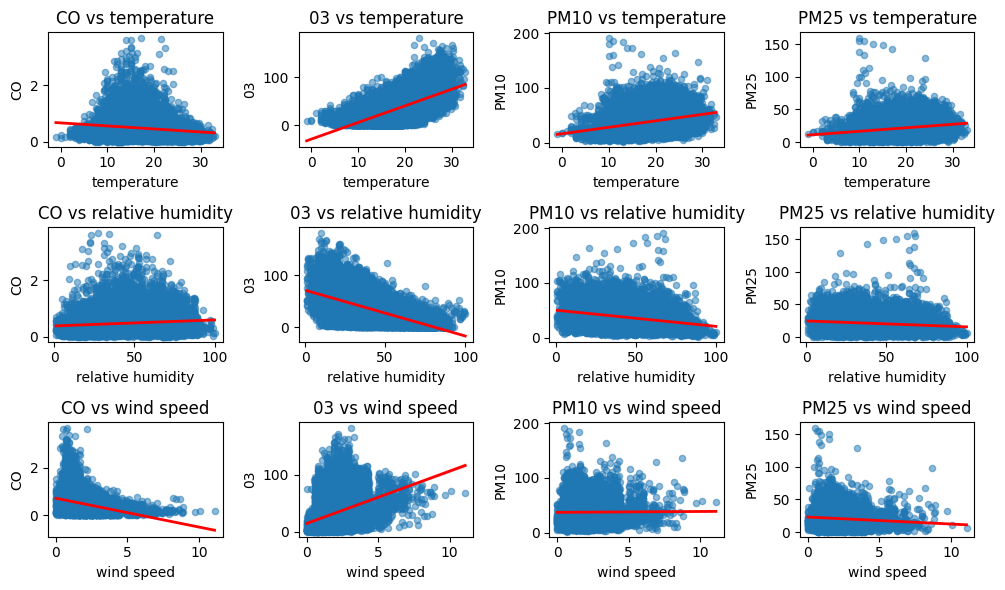

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(
    nrows=3,
    ncols=4,
    figsize=(10, 6)
)

pollutants = ['CO', '03', 'PM10', 'PM25']
meteo = ['temperature', 'relative humidity', 'wind speed']



for i, met in enumerate(meteo):
    for j, pol in enumerate(pollutants):

        sns.regplot(
            data= Cl_whole_poll,
            x=met,
            y=pol,
            scatter_kws={"alpha": 0.5, "s": 20},
            line_kws={"color": "red", "linewidth": 2},
            ax=axes[i, j]
        )

        axes[i, j].set_title(f'{pol} vs {met}')

plt.tight_layout()
plt.show()

In [ ]:


met_vars = ['temperature', 'relative humidity', 'wind speed', 'wind direction']
pollutants = ['CO', '03', 'PM10', 'PM25']

X = Cl_whole_poll[met_vars].values

# --- BEFORE scaling ---
print("BEFORE SCALING:")
print(pd.DataFrame(X, columns=met_vars).describe().round(2))
scaler_X = RobustScaler()

# Sort by time first
Cl_whole_poll = Cl_whole_poll.sort_values('HORA')

X = Cl_whole_poll[met_vars].values
split = int(len(X) * 0.75)

X_train, X_test = X[:split], X[split:]

for pollutant in pollutants:
    y = Cl_whole_poll[pollutant].values
    y_train, y_test = y[:split], y[split:]

#for pollutant in pollutants:
#    y = Cl_whole_poll[pollutant].values

#    X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

    # Scale X
    X_train_scaled = scaler_X.fit_transform(X_train)
    X_test_scaled  = scaler_X.transform(X_test)

    # Scale y
    scaler_y = RobustScaler()
    y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1)).ravel()
    y_test_scaled  = scaler_y.transform(y_test.reshape(-1, 1)).ravel()

    lr = LinearRegression()
    lr.fit(X_train_scaled, y_train_scaled)

    print(f"\nTarget: {pollutant}")
    print(f"  Training R²: {lr.score(X_train_scaled, y_train_scaled):.4f}")
    print(f"  Test R²:     {lr.score(X_test_scaled, y_test_scaled):.4f}")

# --- AFTER scaling ---
print("\nAFTER SCALING:")
print(pd.DataFrame(X_train_scaled, columns=met_vars).describe().round(2))


BEFORE SCALING:
       temperature  relative humidity  wind speed  wind direction
count     11475.00           11475.00    11475.00        11475.00
mean         17.94              43.30        2.06          188.41
std           5.39              20.93        1.17          116.17
min          -1.00               1.00        0.00            0.00
25%          14.10              27.00        1.30           80.00
50%          17.90              41.00        1.90          200.00
75%          21.80              60.00        2.60          303.00
max          32.90             100.00       11.10          360.00

Target: CO
  Training R²: 0.1497
  Test R²:     0.0220

Target: 03
  Training R²: 0.5914
  Test R²:     -0.5185

Target: PM10
  Training R²: 0.1663
  Test R²:     0.0586

Target: PM25
  Training R²: 0.1133
  Test R²:     -0.0609

AFTER SCALING:
       temperature  relative humidity  wind speed  wind direction
count      8606.00            8606.00     8606.00         8606.00
mean        

In [ ]:
print(f"Train: rows 0 to {split}")
print(f"Test:  rows {split} to {len(X)}")


Train: rows 0 to 8606
Test:  rows 8606 to 11475


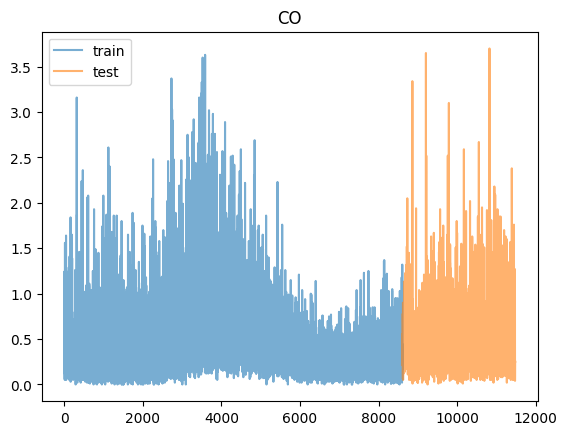

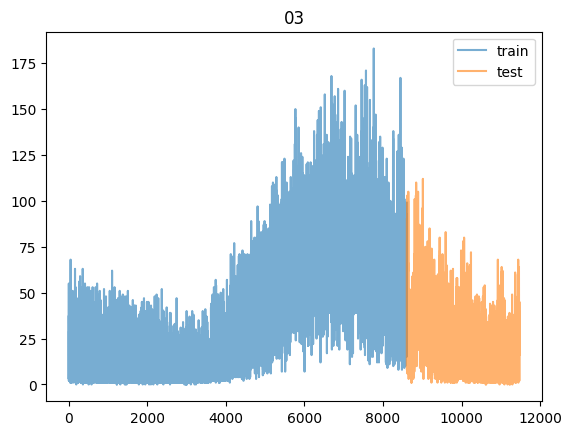

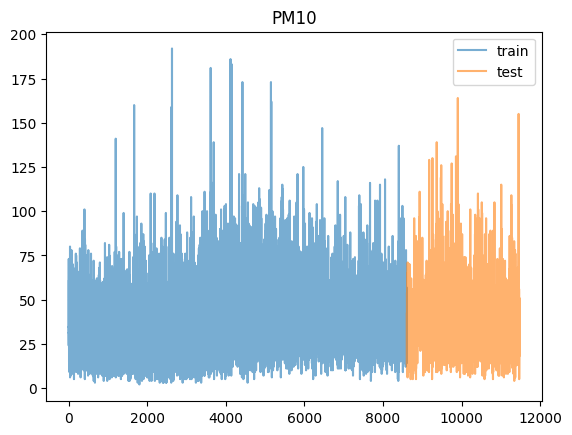

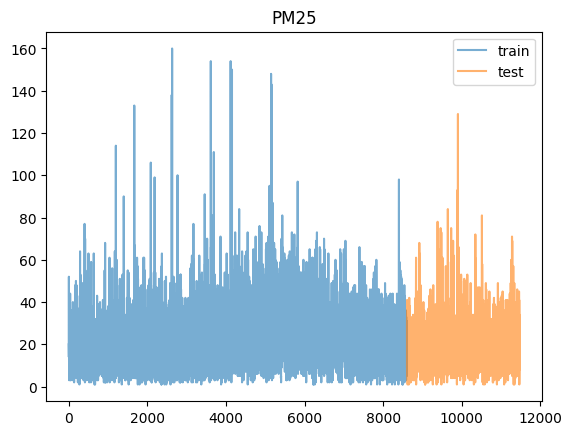

In [ ]:
import matplotlib.pyplot as plt

for pollutant in pollutants:
    y = Cl_whole_poll[pollutant].values
    plt.figure()
    plt.plot(y[:split], label='train', alpha=0.6)
    plt.plot(range(split, len(y)), y[split:], label='test', alpha=0.6)
    plt.title(pollutant)
    plt.legend()
    plt.show()


#Machine Learning

Random forest last dataset with only 3 stations

Training R²: 0.9834
Test R²:     0.8383


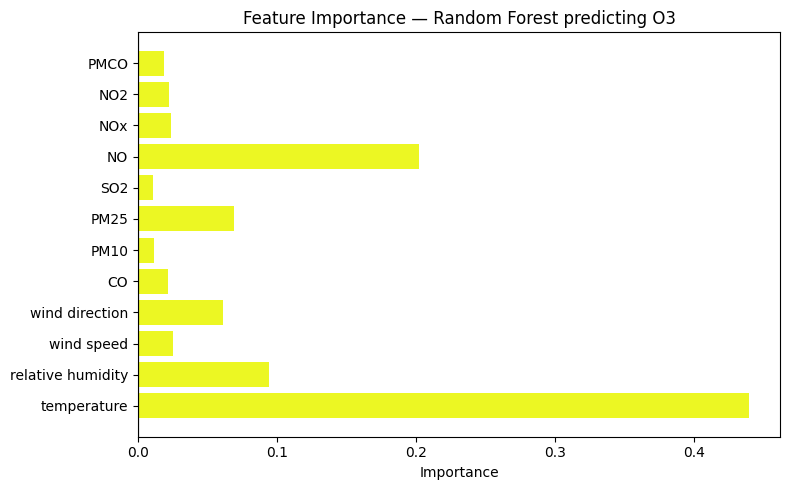

In [ ]:
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt

# Features: meteorological variables + other pollutants
feature_vars = ['temperature', 'relative humidity', 'wind speed', 'wind direction', 'CO', 'PM10', 'PM25', 'SO2', 'NO', 'NOx', 'NO2', 'PMCO']

X_rf = Cl_whole_poll2[feature_vars].values
y_rf = Cl_whole_poll2['03'].values

# Chronological split per month
train_idx_rf = []
test_idx_rf  = []

Cl_whole_poll_reset = Cl_whole_poll2.reset_index(drop=True)

for month, group in Cl_whole_poll_reset.groupby(Cl_whole_poll_reset['FECHA'].dt.month):
    split = int(len(group) * 0.75)
    train_idx_rf.extend(group.index[:split].tolist())
    test_idx_rf.extend(group.index[split:].tolist())

X_train_rf, X_test_rf = X_rf[train_idx_rf], X_rf[test_idx_rf]
y_train_rf, y_test_rf = y_rf[train_idx_rf], y_rf[test_idx_rf]

# Fit Random Forest
rf = RandomForestRegressor(random_state=42, n_estimators=100)
rf.fit(X_train_rf, y_train_rf)

print(f"Training R²: {rf.score(X_train_rf, y_train_rf):.4f}")
print(f"Test R²:     {rf.score(X_test_rf,  y_test_rf):.4f}")

# Plot feature importance
importances = rf.feature_importances_

plt.figure(figsize=(8, 5))
plt.barh(feature_vars, importances, color='#ecf723')
plt.xlabel('Importance')
plt.title('Feature Importance — Random Forest predicting O3')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

100 as number of estimators

Training R²: 0.8306
Test R²:     0.6968


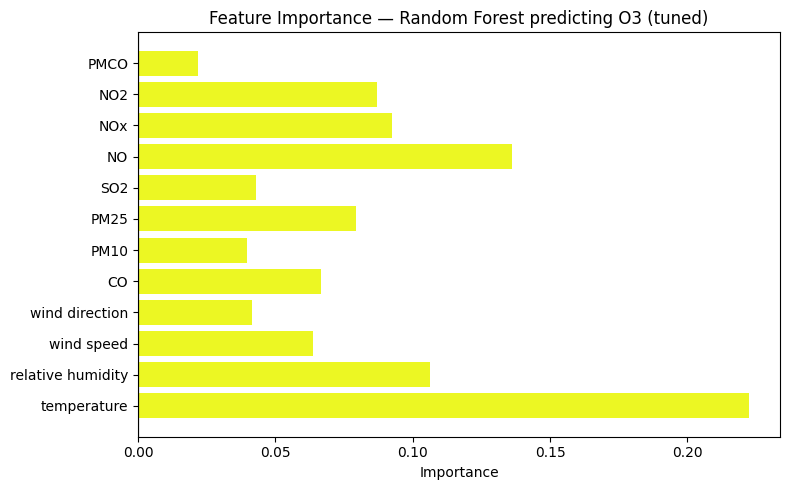

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, PredefinedSplit
import matplotlib.pyplot as plt
import numpy as np

# Features: meteorological variables + other pollutants
feature_vars = ['temperature', 'relative humidity', 'wind speed', 'wind direction', 'CO', 'PM10', 'PM25', 'SO2', 'NO', 'NOx', 'NO2', 'PMCO']

X_rf3 = airquality_pop[feature_vars].values
y_rf3 = airquality_pop['03'].values

# Chronological split per month
train_idx_rf3 = []
test_idx_rf3  = []

airquality_pop_reset = airquality_pop.reset_index(drop=True)

for month, group in airquality_pop_reset.groupby(airquality_pop_reset['FECHA'].dt.month):
    split = int(len(group) * 0.75)
    train_idx_rf3.extend(group.index[:split].tolist())
    test_idx_rf3.extend(group.index[split:].tolist())

X_train_rf3, X_test_rf3 = X_rf3[train_idx_rf3], X_rf3[test_idx_rf3]
y_train_rf3, y_test_rf3 = y_rf3[train_idx_rf3], y_rf3[test_idx_rf3]

# --- NEW: build a validation split (last 20% of the training set, per month)
# so GridSearchCV respects chronological order instead of shuffling
val_fold = np.full(len(train_idx_rf3), -1)  # -1 = always train
train_idx_arr = np.array(train_idx_rf3)

# Mark the most recent ~20% of each month's TRAIN portion as validation
for month, group in airquality_pop_reset.groupby(airquality_pop_reset['FECHA'].dt.month):
    month_train_mask = np.isin(train_idx_arr, group.index[:int(len(group) * 0.75)])
    month_train_positions = np.where(month_train_mask)[0]
    if len(month_train_positions) > 0:
        val_cut = int(len(month_train_positions) * 0.8)
        val_fold[month_train_positions[val_cut:]] = 0  # 0 = validation fold

ps = PredefinedSplit(test_fold=val_fold)


rf3 = RandomForestRegressor(random_state=42, n_estimators=100, min_samples_leaf= 5, max_features= 0.5)

rf3.fit(X_train_rf3, y_train_rf3)

print(f"Training R²: {rf3.score(X_train_rf3, y_train_rf3):.4f}")
print(f"Test R²:     {rf3.score(X_test_rf3,  y_test_rf3):.4f}")

# Plot feature importance
importances = rf.feature_importances_

plt.figure(figsize=(8, 5))
plt.barh(feature_vars, importances, color='#ecf723')
plt.xlabel('Importance')
plt.title('Feature Importance — Random Forest predicting O3 (tuned)')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predictions
y_train_pred3 = rf3.predict(X_train_rf3)
y_test_pred3 = rf3.predict(X_test_rf3)

# Metrics
train_mae3 = mean_absolute_error(y_train_rf3, y_train_pred3)
test_mae3 = mean_absolute_error(y_test_rf3, y_test_pred3)


print(f"Training R²:   {rf3.score(X_train_rf3, y_train_rf3):.4f}")
print(f"Test R²:       {rf3.score(X_test_rf3, y_test_rf3):.4f}")
print(f"Training MAE:  {train_mae3:.4f}")
print(f"Test MAE:      {test_mae3:.4f}")

Training R²:   0.8306
Test R²:       0.6968
Training MAE:  7.9183
Test MAE:      11.9034


1000 as number of estimators









In [ ]:
airquality_pop.shape[1]

18

Training R²: 0.8313
Test R²:     0.6982


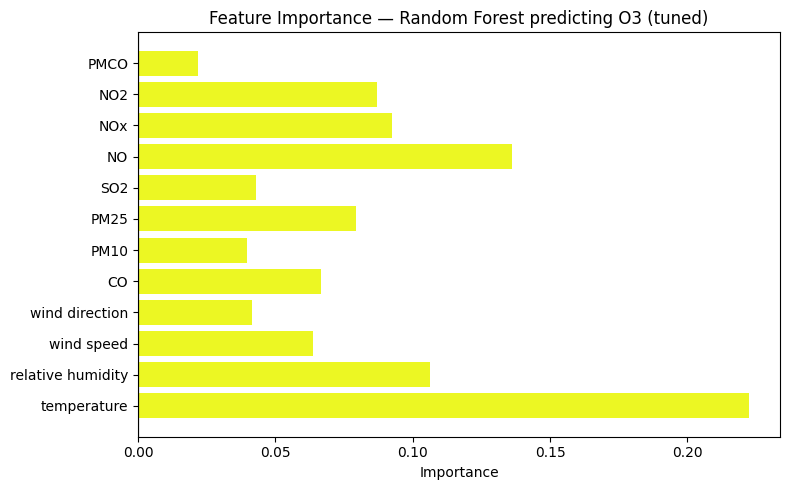

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, PredefinedSplit
import matplotlib.pyplot as plt
import numpy as np

# Features: meteorological variables + other pollutants
feature_vars = ['temperature', 'relative humidity', 'wind speed', 'wind direction', 'CO', 'PM10', 'PM25', 'SO2', 'NO', 'NOx', 'NO2', 'PMCO']

X_rf2 = airquality_pop[feature_vars].values
y_rf2 = airquality_pop['03'].values

# Chronological split per month
train_idx_rf2 = []
test_idx_rf2  = []

airquality_pop_reset = airquality_pop.reset_index(drop=True)

for month, group in airquality_pop_reset.groupby(airquality_pop_reset['FECHA'].dt.month):
    split = int(len(group) * 0.75)
    train_idx_rf2.extend(group.index[:split].tolist())
    test_idx_rf2.extend(group.index[split:].tolist())

X_train_rf2, X_test_rf2 = X_rf2[train_idx_rf2], X_rf2[test_idx_rf2]
y_train_rf2, y_test_rf2 = y_rf2[train_idx_rf2], y_rf2[test_idx_rf2]

# --- NEW: build a validation split (last 20% of the training set, per month)
# so GridSearchCV respects chronological order instead of shuffling
val_fold = np.full(len(train_idx_rf2), -1)  # -1 = always train
train_idx_arr = np.array(train_idx_rf2)

# Mark the most recent ~20% of each month's TRAIN portion as validation
for month, group in airquality_pop_green_reset.groupby(airquality_pop_green_reset['FECHA'].dt.month):
    month_train_mask = np.isin(train_idx_arr, group.index[:int(len(group) * 0.75)])
    month_train_positions = np.where(month_train_mask)[0]
    if len(month_train_positions) > 0:
        val_cut = int(len(month_train_positions) * 0.8)
        val_fold[month_train_positions[val_cut:]] = 0  # 0 = validation fold

ps = PredefinedSplit(test_fold=val_fold)


rf2 = RandomForestRegressor(random_state=42, n_estimators=1000, min_samples_leaf= 5, max_features= 0.5)

rf2.fit(X_train_rf2, y_train_rf2)

print(f"Training R²: {rf2.score(X_train_rf2, y_train_rf2):.4f}")
print(f"Test R²:     {rf2.score(X_test_rf2,  y_test_rf2):.4f}")

# Plot feature importance
importances = rf.feature_importances_

plt.figure(figsize=(8, 5))
plt.barh(feature_vars, importances, color='#ecf723')
plt.xlabel('Importance')
plt.title('Feature Importance — Random Forest predicting O3 (tuned)')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predictions
y_train_pred = rf2.predict(X_train_rf2)
y_test_pred = rf2.predict(X_test_rf2)

# Metrics
train_mae2 = mean_absolute_error(y_train_rf2, y_train_pred)
test_mae2 = mean_absolute_error(y_test_rf2, y_test_pred)

train_rmse = np.sqrt(mean_squared_error(y_train_rf2, y_train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test_rf2, y_test_pred))

print(f"Training R²:   {rf2.score(X_train_rf2, y_train_rf2):.4f}")
print(f"Test R²:       {rf2.score(X_test_rf2, y_test_rf2):.4f}")
print(f"Training MAE:  {train_mae2:.4f}")
print(f"Test MAE:      {test_mae2:.4f}")

Training R²:   0.8313
Test R²:       0.6982
Training MAE:  7.9009
Test MAE:      11.8932


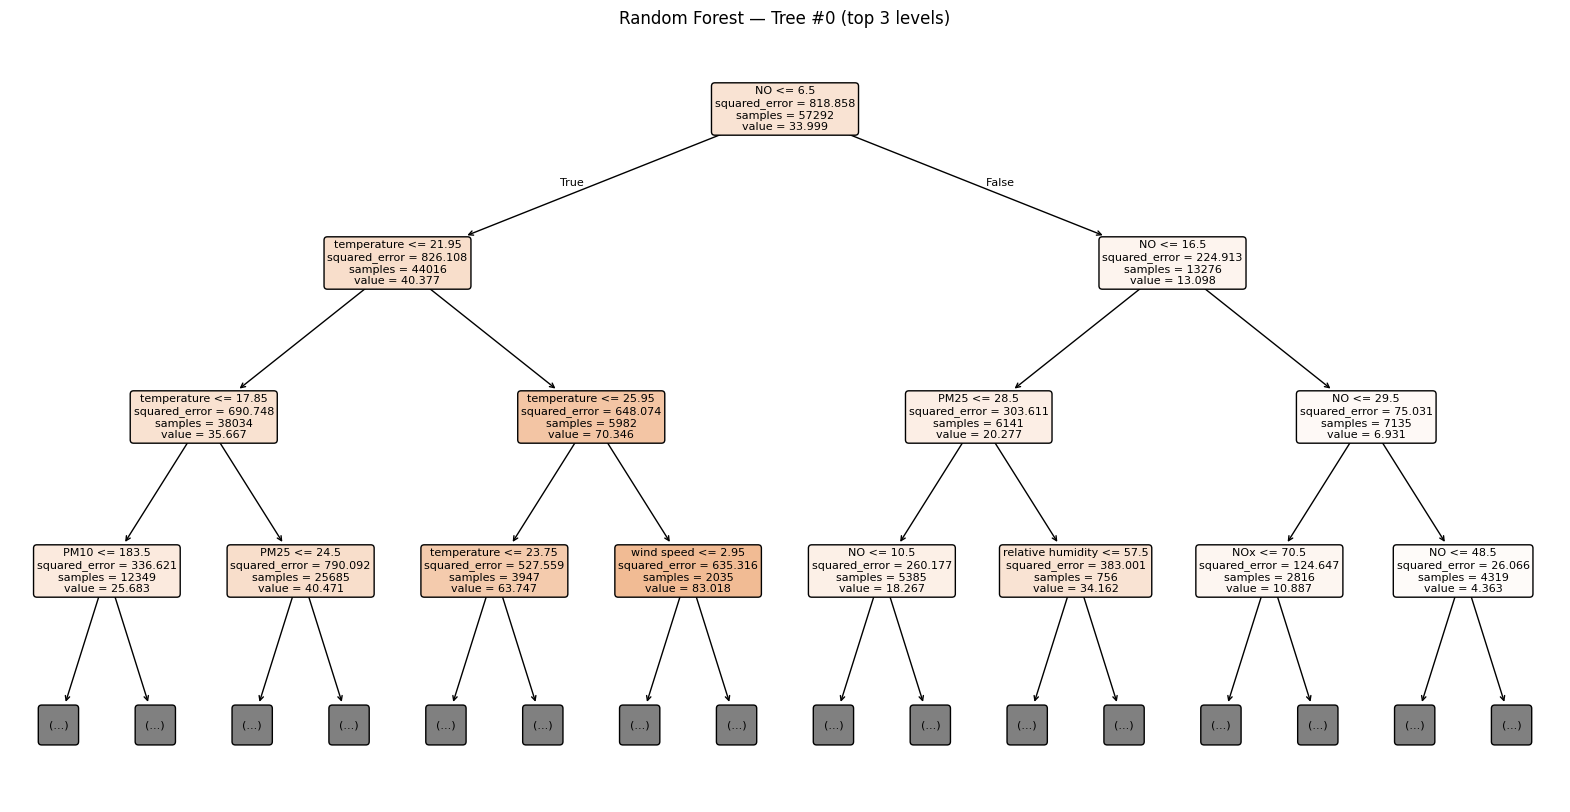

In [ ]:
from sklearn.tree import plot_tree

# Look at just one tree, e.g. the first one
plt.figure(figsize=(20, 10))
plot_tree(
    rf2.estimators_[0],
    feature_names=feature_vars,
    filled=True,
    rounded=True,
    max_depth=3,        # limit depth shown, or the plot becomes unreadable
    fontsize=8
)
plt.title('Random Forest — Tree #0 (top 3 levels)')
plt.show()

model with the default features and 100 as number of estimators

Training R²: 0.9304
Test R²:     0.6889


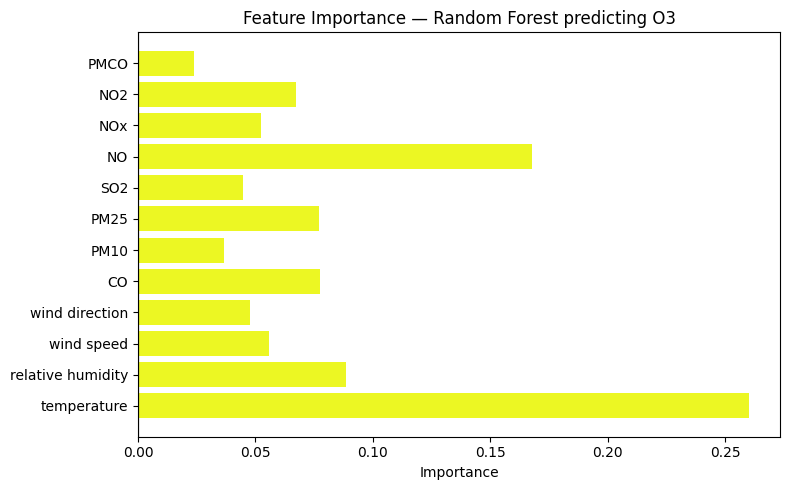

In [ ]:
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt

# Features: meteorological variables + other pollutants
feature_vars = ['temperature', 'relative humidity', 'wind speed', 'wind direction', 'CO', 'PM10', 'PM25', 'SO2', 'NO', 'NOx', 'NO2', 'PMCO']

X_rf = airquality_pop_green[feature_vars].values
y_rf = airquality_pop_green['03'].values

# Chronological split per month
train_idx_rf = []
test_idx_rf  = []

airquality_pop_green_reset = airquality_pop_green.reset_index(drop=True)

for month, group in airquality_pop_green_reset.groupby(airquality_pop_green_reset['FECHA'].dt.month):
    split = int(len(group) * 0.75)
    train_idx_rf.extend(group.index[:split].tolist())
    test_idx_rf.extend(group.index[split:].tolist())

X_train_rf, X_test_rf = X_rf[train_idx_rf], X_rf[test_idx_rf]
y_train_rf, y_test_rf = y_rf[train_idx_rf], y_rf[test_idx_rf]

# Fit Random Forest
rf = RandomForestRegressor(random_state=42, n_estimators=100)
rf.fit(X_train_rf, y_train_rf)

print(f"Training R²: {rf.score(X_train_rf, y_train_rf):.4f}")
print(f"Test R²:     {rf.score(X_test_rf,  y_test_rf):.4f}")

# Plot feature importance
importances = rf.feature_importances_

plt.figure(figsize=(8, 5))
plt.barh(feature_vars, importances, color='#ecf723')
plt.xlabel('Importance')
plt.title('Feature Importance — Random Forest predicting O3')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predictions
y_train_pred = rf.predict(X_train_rf)
y_test_pred = rf.predict(X_test_rf)

# Metrics
train_mae = mean_absolute_error(y_train_rf, y_train_pred)
test_mae = mean_absolute_error(y_test_rf, y_test_pred)

train_rmse = np.sqrt(mean_squared_error(y_train_rf, y_train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test_rf, y_test_pred))

print(f"Training R²:   {rf.score(X_train_rf, y_train_rf):.4f}")
print(f"Test R²:       {rf.score(X_test_rf, y_test_rf):.4f}")
print(f"Training MAE:  {train_mae:.4f}")
print(f"Test MAE:      {test_mae:.4f}")
print(f"Training RMSE: {train_rmse:.4f}")
print(f"Test RMSE:     {test_rmse:.4f}")

Training R²:   0.9304
Test R²:       0.6889
Training MAE:  4.5868
Test MAE:      11.9839
Training RMSE: 7.5549
Test RMSE:     17.2636


linear regression


Training R²:  0.6946
Test R²:      0.6921
Training MAE: 12.2925
Test MAE:     13.0245


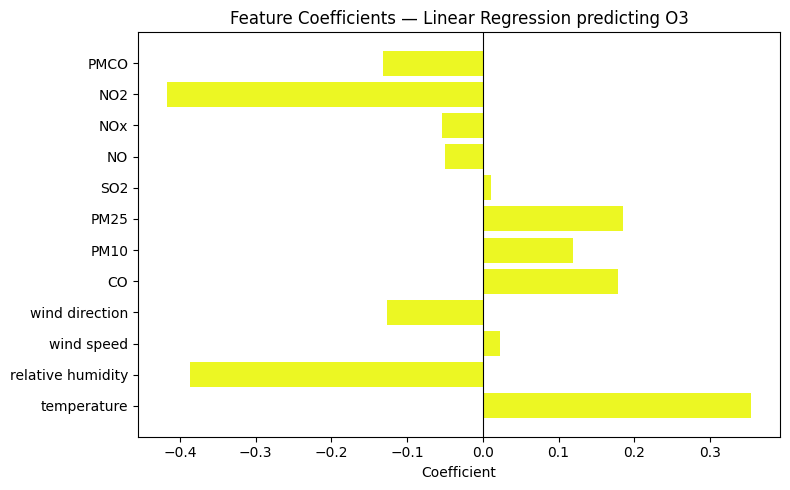

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import r2_score, mean_absolute_error
import matplotlib.pyplot as plt

feature_vars = ['temperature', 'relative humidity', 'wind speed', 'wind direction', 'CO', 'PM10', 'PM25', 'SO2', 'NO', 'NOx', 'NO2', 'PMCO']

X_lr = Cl_whole_poll2[feature_vars].values
y_lr = Cl_whole_poll2['03'].values  # ← O3 not 03

# Chronological split per month
train_idx_lr = []
test_idx_lr  = []

Cl_whole_poll_reset = Cl_whole_poll2.reset_index(drop=True)

for month, group in Cl_whole_poll_reset.groupby(Cl_whole_poll_reset['FECHA'].dt.month):
    split = int(len(group) * 0.75)
    train_idx_lr.extend(group.index[:split].tolist())
    test_idx_lr.extend(group.index[split:].tolist())

X_train_lr, X_test_lr = X_lr[train_idx_lr], X_lr[test_idx_lr]
y_train_lr, y_test_lr = y_lr[train_idx_lr], y_lr[test_idx_lr]

# Scale
scaler_X = RobustScaler()
X_train_scaled = scaler_X.fit_transform(X_train_lr)
X_test_scaled  = scaler_X.transform(X_test_lr)

scaler_y = RobustScaler()
y_train_scaled = scaler_y.fit_transform(y_train_lr.reshape(-1, 1)).ravel()
y_test_scaled  = scaler_y.transform(y_test_lr.reshape(-1, 1)).ravel()

# Fit Linear Regression
lr = LinearRegression()
lr.fit(X_train_scaled, y_train_scaled)

# Inverse transform predictions to original scale
y_train_pred = scaler_y.inverse_transform(lr.predict(X_train_scaled).reshape(-1, 1)).ravel()
y_test_pred  = scaler_y.inverse_transform(lr.predict(X_test_scaled).reshape(-1, 1)).ravel()

print(f"Training R²:  {r2_score(y_train_lr, y_train_pred):.4f}")
print(f"Test R²:      {r2_score(y_test_lr,  y_test_pred):.4f}")
print(f"Training MAE: {mean_absolute_error(y_train_lr, y_train_pred):.4f}")
print(f"Test MAE:     {mean_absolute_error(y_test_lr,  y_test_pred):.4f}")

# Plot coefficients
plt.figure(figsize=(8, 5))
plt.barh(feature_vars, lr.coef_, color='#ecf723')
plt.xlabel('Coefficient')
plt.title('Feature Coefficients — Linear Regression predicting O3')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

Ridge

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import r2_score, mean_absolute_error

feature_vars = ['temperature', 'relative humidity', 'wind speed', 'wind direction', 'CO', 'PM10', 'PM25', 'SO2', 'NO', 'NOx', 'NO2', 'PMCO']

X_ridge = Cl_whole_poll2[feature_vars].values
y_ridge = Cl_whole_poll2['03'].values

# Chronological split per month
train_idx_ridge = []
test_idx_ridge  = []

Cl_whole_poll_reset = Cl_whole_poll2.reset_index(drop=True)

for month, group in Cl_whole_poll_reset.groupby(Cl_whole_poll_reset['FECHA'].dt.month):
    split = int(len(group) * 0.75)
    train_idx_ridge.extend(group.index[:split].tolist())
    test_idx_ridge.extend(group.index[split:].tolist())

X_train_r, X_test_r = X_ridge[train_idx_ridge], X_ridge[test_idx_ridge]
y_train_r, y_test_r = y_ridge[train_idx_ridge], y_ridge[test_idx_ridge]

# Scale
scaler_X = RobustScaler()
X_train_scaled = scaler_X.fit_transform(X_train_r)
X_test_scaled  = scaler_X.transform(X_test_r)

scaler_y = RobustScaler()
y_train_scaled = scaler_y.fit_transform(y_train_r.reshape(-1, 1)).ravel()
y_test_scaled  = scaler_y.transform(y_test_r.reshape(-1, 1)).ravel()

# Fit Ridge — alpha controls regularization strength (higher = more shrinkage)
ridge = Ridge(alpha=1.0, random_state=42)
ridge.fit(X_train_scaled, y_train_scaled)

# Inverse transform predictions to original scale
y_train_pred = scaler_y.inverse_transform(ridge.predict(X_train_scaled).reshape(-1, 1)).ravel()
y_test_pred  = scaler_y.inverse_transform(ridge.predict(X_test_scaled).reshape(-1, 1)).ravel()

print(f"Training R²:  {r2_score(y_train_r, y_train_pred):.4f}")
print(f"Test R²:      {r2_score(y_test_r,  y_test_pred):.4f}")
print(f"Training MAE: {mean_absolute_error(y_train_r, y_train_pred):.4f}")
print(f"Test MAE:     {mean_absolute_error(y_test_r,  y_test_pred):.4f}")

for alpha in [0.01, 1, 10, 100, 1000]:
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train_scaled, y_train_scaled)
    y_test_pred = scaler_y.inverse_transform(ridge.predict(X_test_scaled).reshape(-1, 1)).ravel()
    print(f"alpha={alpha:<6} Test R²: {r2_score(y_test_r, y_test_pred):.4f}  MAE: {mean_absolute_error(y_test_r, y_test_pred):.4f}")

Training R²:  0.6946
Test R²:      0.6921
Training MAE: 12.2919
Test MAE:     13.0239
alpha=0.01   Test R²: 0.6921  MAE: 13.0245
alpha=1      Test R²: 0.6921  MAE: 13.0239
alpha=10     Test R²: 0.6923  MAE: 13.0201
alpha=100    Test R²: 0.6934  MAE: 12.9960
alpha=1000   Test R²: 0.6774  MAE: 13.3463


Neural networks

In [ ]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import r2_score, mean_absolute_error

# -----------------------------
# Features and target
# -----------------------------
feature_vars = [
    'temperature', 'relative humidity', 'wind speed', 'wind direction',
    'CO', 'PM10', 'PM25', 'SO2', 'NO', 'NOx', 'NO2', 'PMCO'
]

X_nn = airquality_pop[feature_vars].values
y_nn_log = np.log1p(airquality_pop['03'].values)

# -----------------------------
# Chronological split (by month)
# -----------------------------
airquality_pop_reset= airquality_pop.reset_index(drop=True)

train_idx, test_idx = [], []

for _, group in airquality_pop_reset.groupby(airquality_pop_reset['FECHA'].dt.month):
    split = int(len(group) * 0.75)
    train_idx.extend(group.index[:split].tolist())
    test_idx.extend(group.index[split:].tolist())

X_train, X_test = X_nn[train_idx], X_nn[test_idx]
y_train_log, y_test_log = y_nn_log[train_idx], y_nn_log[test_idx]

In [ ]:
X_train

array([[  6. ,  57. ,   3.5, ...,  10. ,  10. ,  11. ],
       [  1. ,  99. ,   0.9, ...,   nan,   nan,   nan],
       [ 12. ,  56. ,   0.8, ...,   nan,  43. ,  20. ],
       ...,
       [  nan, -99. ,   nan, ...,   nan,   nan,  15. ],
       [  nan,   nan,   nan, ...,  33. ,  29. ,   nan],
       [ 18.9,  32. ,   1.8, ...,  48. ,  40. ,  10. ]])

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Impute first
imputer = SimpleImputer(strategy='mean')

X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

X_train_imp

array([[  6.        ,  57.        ,   3.5       , ...,  10.        ,
         10.        ,  11.        ],
       [  1.        ,  99.        ,   0.9       , ...,  35.48941689,
         23.73064317,  18.20309938],
       [ 12.        ,  56.        ,   0.8       , ...,  35.48941689,
         43.        ,  20.        ],
       ...,
       [ 17.20498861, -99.        ,   2.12294664, ...,  35.48941689,
         23.73064317,  15.        ],
       [ 17.20498861,   9.70977227,   2.12294664, ...,  33.        ,
         29.        ,  18.20309938],
       [ 18.9       ,  32.        ,   1.8       , ...,  48.        ,
         40.        ,  10.        ]])

Training R²: 0.6433
Training MAE:11.7827
Test R²:     0.6307
Test MAE:    12.8399
Converged:   True


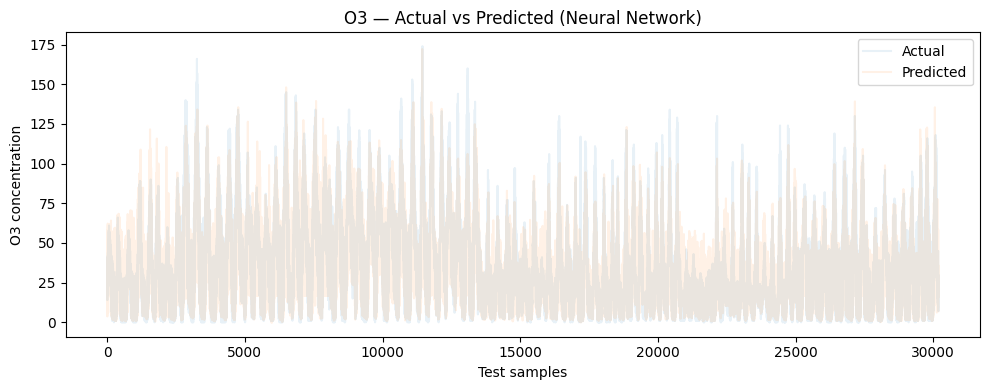

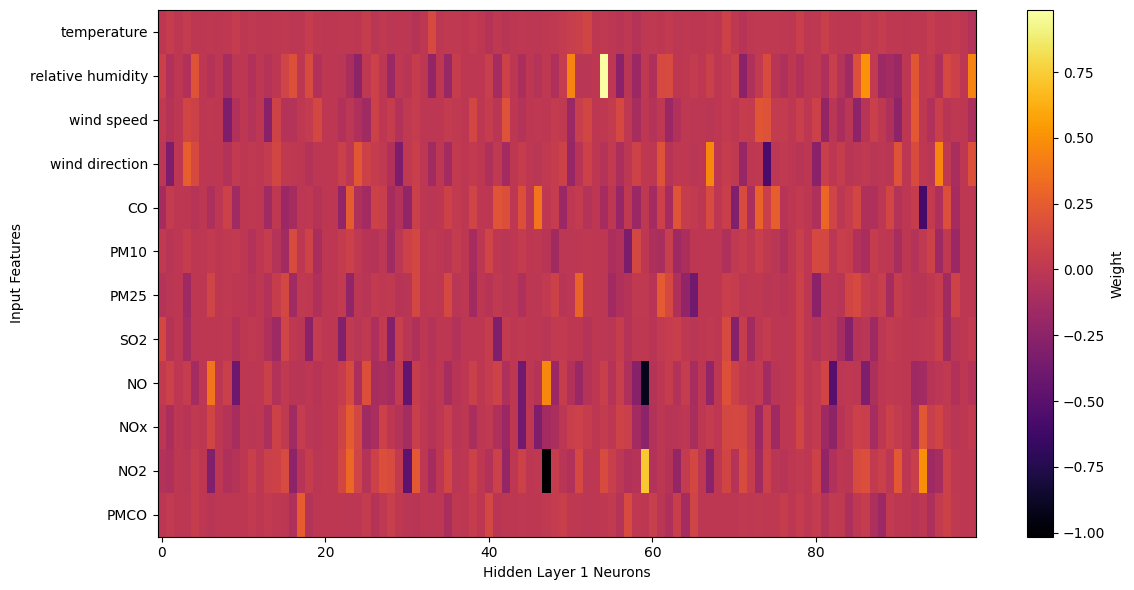

In [ ]:
# -----------------------------
# Scaling
# -----------------------------
scaler_X = RobustScaler()
X_train_scaled = scaler_X.fit_transform(X_train_imp)
X_test_scaled  = scaler_X.transform(X_test_imp)

scaler_y = RobustScaler()
y_train_scaled = scaler_y.fit_transform(y_train_log.reshape(-1, 1)).ravel()

# -----------------------------
# Model
# -----------------------------
mlp = MLPRegressor(
    hidden_layer_sizes=(100, 100),
    activation='relu',
    random_state=42,
    max_iter=10000,
    alpha=0.1
)

mlp.fit(X_train_scaled, y_train_scaled)

# -----------------------------
# Predictions (scaled → log → original)
# -----------------------------
y_train_pred_scaled = mlp.predict(X_train_scaled)
y_test_pred_scaled  = mlp.predict(X_test_scaled)

y_train_pred_log = scaler_y.inverse_transform(
    y_train_pred_scaled.reshape(-1, 1)
).ravel()

y_test_pred_log = scaler_y.inverse_transform(
    y_test_pred_scaled.reshape(-1, 1)
).ravel()

# back to original O3 scale
y_train_orig = np.expm1(y_train_log)
y_test_orig = np.expm1(y_test_log)

y_train_pred_orig = np.expm1(y_train_pred_log)
y_test_pred_orig = np.expm1(y_test_pred_log)

# -----------------------------
# Metrics (ORIGINAL SCALE)
# -----------------------------
print(f"Training R²: {r2_score(y_train_orig, y_train_pred_orig):.4f}")
print(f"Training MAE:{mean_absolute_error(y_train_orig, y_train_pred_orig):.4f}")
print(f"Test R²:     {r2_score(y_test_orig, y_test_pred_orig):.4f}")
print(f"Test MAE:    {mean_absolute_error(y_test_orig, y_test_pred_orig):.4f}")
print(f"Converged:   {mlp.n_iter_ < 10000}")

# -----------------------------
# Plot: Actual vs Predicted
# -----------------------------
plt.figure(figsize=(10, 4))
plt.plot(y_test_orig, label='Actual', alpha=0.1)
plt.plot(y_test_pred_orig, label='Predicted', alpha=0.1)
plt.title('O3 — Actual vs Predicted (Neural Network)')
plt.xlabel('Test samples')
plt.ylabel('O3 concentration')
plt.legend()
plt.tight_layout()
plt.show()

# -----------------------------
# HEATMAP: Input → Hidden Layer 1
# -----------------------------
weights = mlp.coefs_[0]

plt.figure(figsize=(12, 6))
plt.imshow(weights, aspect='auto', cmap='inferno', interpolation='none')

plt.yticks(np.arange(len(feature_vars)), feature_vars)

plt.xlabel("Hidden Layer 1 Neurons")
plt.ylabel("Input Features")
plt.colorbar(label="Weight")
plt.tight_layout()
plt.show()

Training R²: 0.5064
Training MAE:13.8682
Test R²:     0.4985
Test MAE:    15.0524
Converged:   True


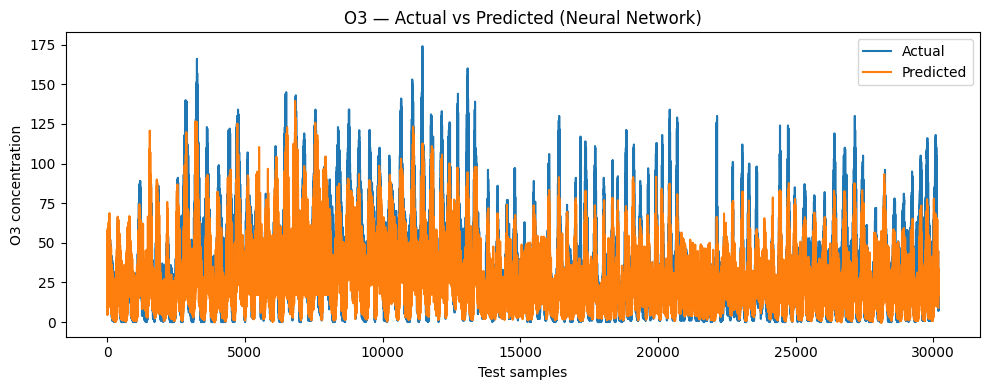

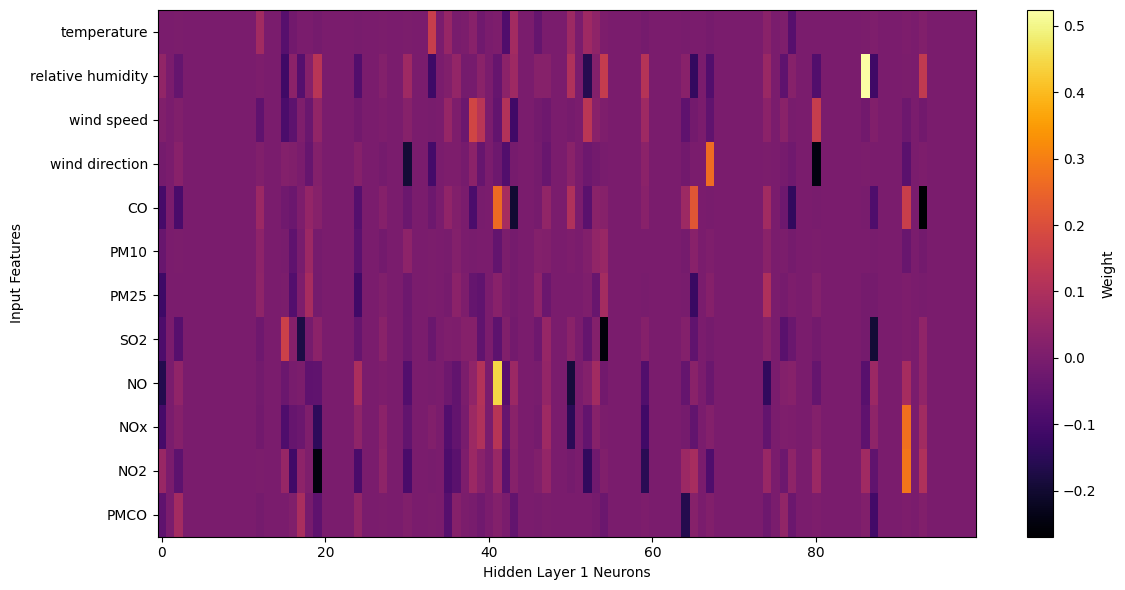

In [ ]:
# -----------------------------
# Model2
# -----------------------------
mlp2 = MLPRegressor(
    hidden_layer_sizes=(100, 100),
    activation='relu',
    random_state=42,
    max_iter=10000,
    alpha=1
)

mlp2.fit(X_train_scaled, y_train_scaled)

# -----------------------------
# Predictions (scaled → log → original)
# -----------------------------
y_train_pred_scaled = mlp2.predict(X_train_scaled)
y_test_pred_scaled  = mlp2.predict(X_test_scaled)

y_train_pred_log = scaler_y.inverse_transform(
    y_train_pred_scaled.reshape(-1, 1)
).ravel()

y_test_pred_log = scaler_y.inverse_transform(
    y_test_pred_scaled.reshape(-1, 1)
).ravel()

# back to original O3 scale
y_train_orig = np.expm1(y_train_log)
y_test_orig = np.expm1(y_test_log)

y_train_pred_orig = np.expm1(y_train_pred_log)
y_test_pred_orig = np.expm1(y_test_pred_log)

# -----------------------------
# Metrics (ORIGINAL SCALE)
# -----------------------------
print(f"Training R²: {r2_score(y_train_orig, y_train_pred_orig):.4f}")
print(f"Training MAE:{mean_absolute_error(y_train_orig, y_train_pred_orig):.4f}")
print(f"Test R²:     {r2_score(y_test_orig, y_test_pred_orig):.4f}")
print(f"Test MAE:    {mean_absolute_error(y_test_orig, y_test_pred_orig):.4f}")
print(f"Converged:   {mlp.n_iter_ < 10000}")

# -----------------------------
# Plot: Actual vs Predicted
# -----------------------------
plt.figure(figsize=(10, 4))
plt.plot(y_test_orig, label='Actual', alpha=1)
plt.plot(y_test_pred_orig, label='Predicted', alpha=1)
plt.title('O3 — Actual vs Predicted (Neural Network)')
plt.xlabel('Test samples')
plt.ylabel('O3 concentration')
plt.legend()
plt.tight_layout()
plt.show()

# -----------------------------
# HEATMAP: Input → Hidden Layer 1
# -----------------------------
weights = mlp2.coefs_[0]

plt.figure(figsize=(12, 6))
plt.imshow(weights, aspect='auto', cmap='inferno', interpolation='none')

plt.yticks(np.arange(len(feature_vars)), feature_vars)

plt.xlabel("Hidden Layer 1 Neurons")
plt.ylabel("Input Features")
plt.colorbar(label="Weight")
plt.tight_layout()
plt.show()

Training R²: 0.5744
Training MAE:12.7398
Test R²:     0.5538
Test MAE:    14.1121
Converged:   True


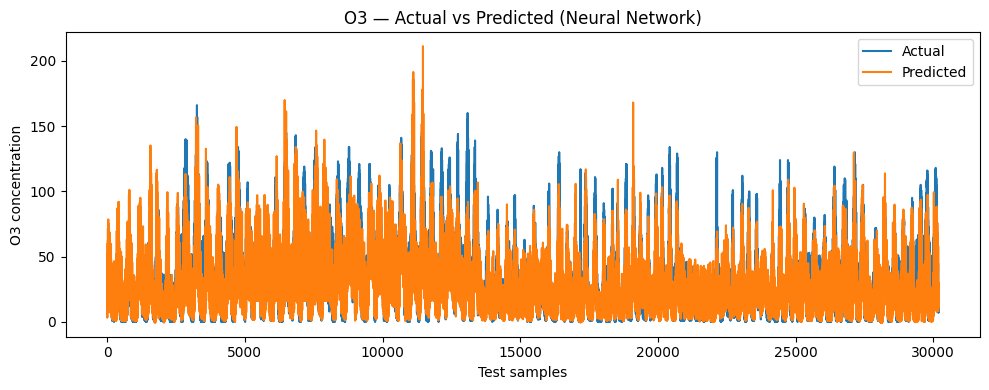

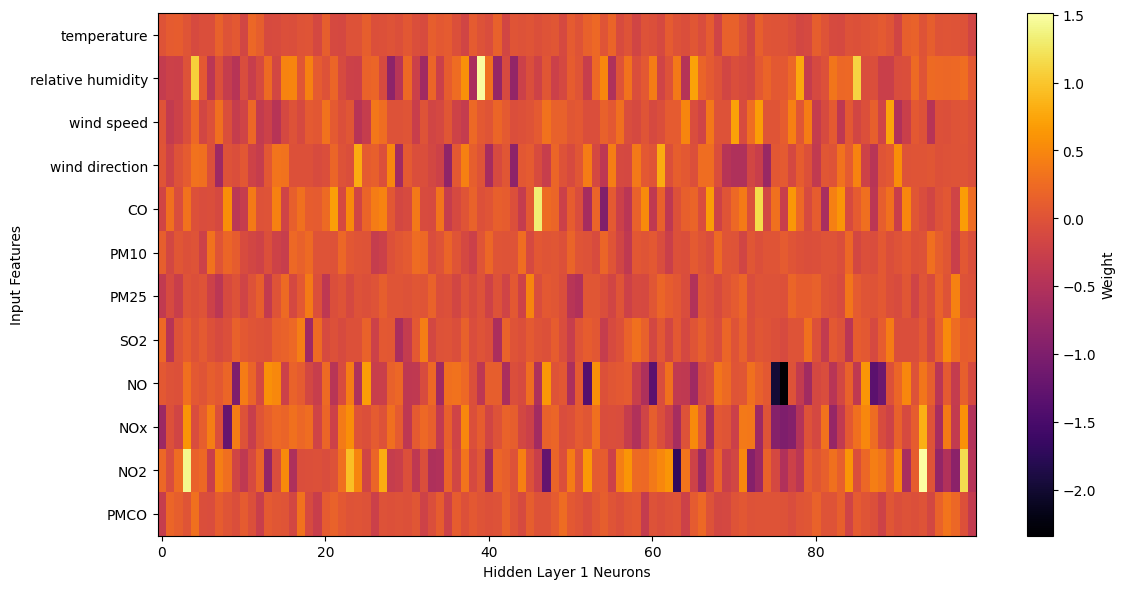

In [ ]:
# -----------------------------
# Model3
# -----------------------------
mlp3 = MLPRegressor(random_state=42)

mlp3.fit(X_train_scaled, y_train_scaled)

# -----------------------------
# Predictions (scaled → log → original)
# -----------------------------
y_train_pred_scaled = mlp3.predict(X_train_scaled)
y_test_pred_scaled  = mlp3.predict(X_test_scaled)

y_train_pred_log = scaler_y.inverse_transform(
    y_train_pred_scaled.reshape(-1, 1)
).ravel()

y_test_pred_log = scaler_y.inverse_transform(
    y_test_pred_scaled.reshape(-1, 1)
).ravel()

# back to original O3 scale
y_train_orig = np.expm1(y_train_log)
y_test_orig = np.expm1(y_test_log)

y_train_pred_orig = np.expm1(y_train_pred_log)
y_test_pred_orig = np.expm1(y_test_pred_log)

# -----------------------------
# Metrics (ORIGINAL SCALE)
# -----------------------------
print(f"Training R²: {r2_score(y_train_orig, y_train_pred_orig):.4f}")
print(f"Training MAE:{mean_absolute_error(y_train_orig, y_train_pred_orig):.4f}")
print(f"Test R²:     {r2_score(y_test_orig, y_test_pred_orig):.4f}")
print(f"Test MAE:    {mean_absolute_error(y_test_orig, y_test_pred_orig):.4f}")
print(f"Converged:   {mlp.n_iter_ < 10000}")

# -----------------------------
# Plot: Actual vs Predicted
# -----------------------------
plt.figure(figsize=(10, 4))
plt.plot(y_test_orig, label='Actual', alpha=1)
plt.plot(y_test_pred_orig, label='Predicted', alpha=1)
plt.title('O3 — Actual vs Predicted (Neural Network)')
plt.xlabel('Test samples')
plt.ylabel('O3 concentration')
plt.legend()
plt.tight_layout()
plt.show()

# -----------------------------
# HEATMAP: Input → Hidden Layer 1
# -----------------------------
weights = mlp3.coefs_[0]

plt.figure(figsize=(12, 6))
plt.imshow(weights, aspect='auto', cmap='inferno', interpolation='none')

plt.yticks(np.arange(len(feature_vars)), feature_vars)

plt.xlabel("Hidden Layer 1 Neurons")
plt.ylabel("Input Features")
plt.colorbar(label="Weight")
plt.tight_layout()
plt.show()

XGBoost

Training R²:  0.5264
Test R²:      0.5290
Training MAE: 14.9373
Test MAE:     16.0243


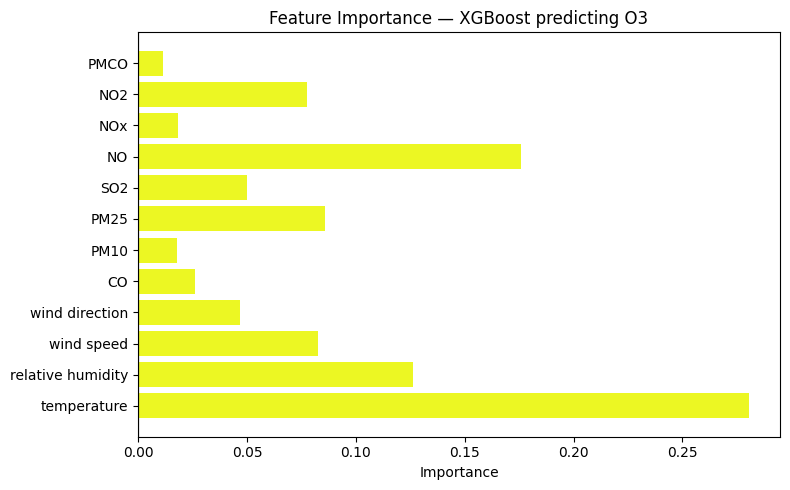

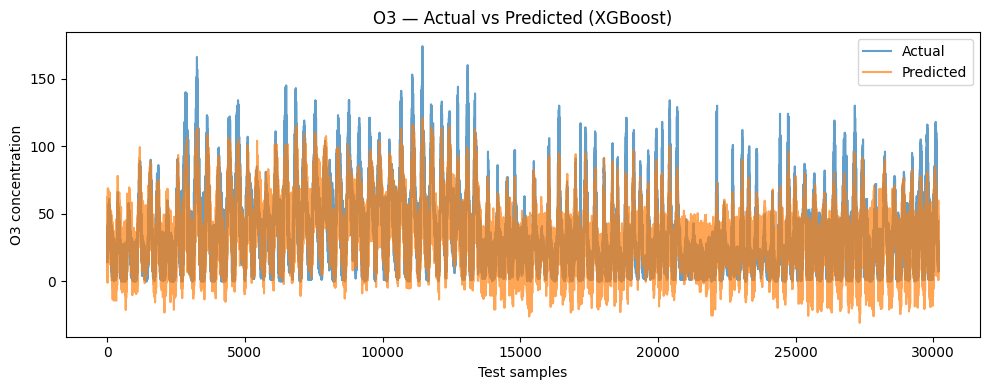

In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error

feature_vars = ['temperature', 'relative humidity', 'wind speed', 'wind direction', 'CO', 'PM10', 'PM25', 'SO2', 'NO', 'NOx', 'NO2', 'PMCO']

# Impute first

X_xgb = airquality_pop[feature_vars].values
y_xgb = airquality_pop['03'].values

# Chronological split per month
train_idx_xgb = []
test_idx_xgb  = []

airquality_pop_reset = airquality_pop.reset_index(drop=True)

for month, group in airquality_pop_reset.groupby(airquality_pop_reset['FECHA'].dt.month):
    split = int(len(group) * 0.75)
    train_idx_xgb.extend(group.index[:split].tolist())
    test_idx_xgb.extend(group.index[split:].tolist())

X_train_xgb, X_test_xgb = X_xgb[train_idx_xgb], X_xgb[test_idx_xgb]
y_train_xgb, y_test_xgb = y_xgb[train_idx_xgb], y_xgb[test_idx_xgb]

# No scaling needed for XGBoost
xgb2 = XGBRegressor(
    n_estimators=100,      # number of trees
    learning_rate=1.5,     # step size per tree
    max_depth=1,           # tree depth
    random_state=42,
)
xgb2.fit(X_train_xgb, y_train_xgb)

y_train_pred = xgb2.predict(X_train_xgb)
y_test_pred  = xgb2.predict(X_test_xgb)

print(f"Training R²:  {r2_score(y_train_xgb, y_train_pred):.4f}")
print(f"Test R²:      {r2_score(y_test_xgb,  y_test_pred):.4f}")
print(f"Training MAE: {mean_absolute_error(y_train_xgb, y_train_pred):.4f}")
print(f"Test MAE:     {mean_absolute_error(y_test_xgb,  y_test_pred):.4f}")

# Plot feature importance
plt.figure(figsize=(8, 5))
plt.barh(feature_vars, xgb2.feature_importances_, color='#ecf723')
plt.xlabel('Importance')
plt.title('Feature Importance — XGBoost predicting O3')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

# Plot actual vs predicted
plt.figure(figsize=(10, 4))
plt.plot(y_test_xgb,  label='Actual',    alpha=0.7)
plt.plot(y_test_pred, label='Predicted', alpha=0.7)
plt.title('O3 — Actual vs Predicted (XGBoost)')
plt.xlabel('Test samples')
plt.ylabel('O3 concentration')
plt.legend()
plt.tight_layout()
plt.show()

Training R²:  0.7091
Test R²:      0.6844
Training MAE: 10.9451
Test MAE:     12.3312


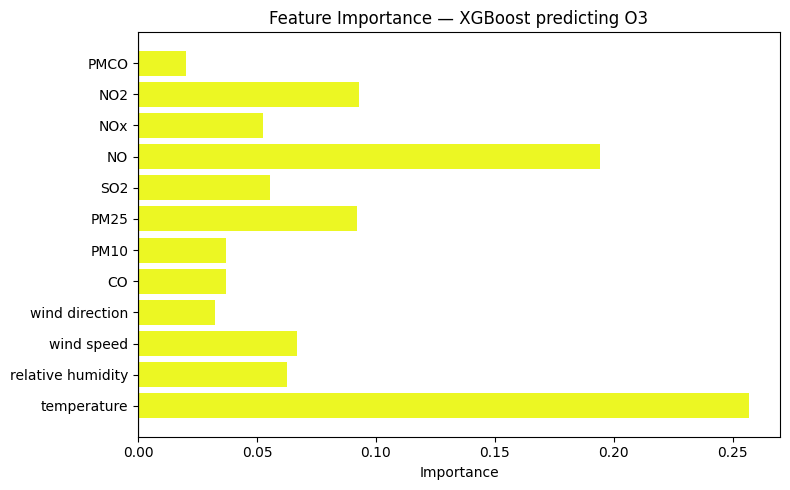

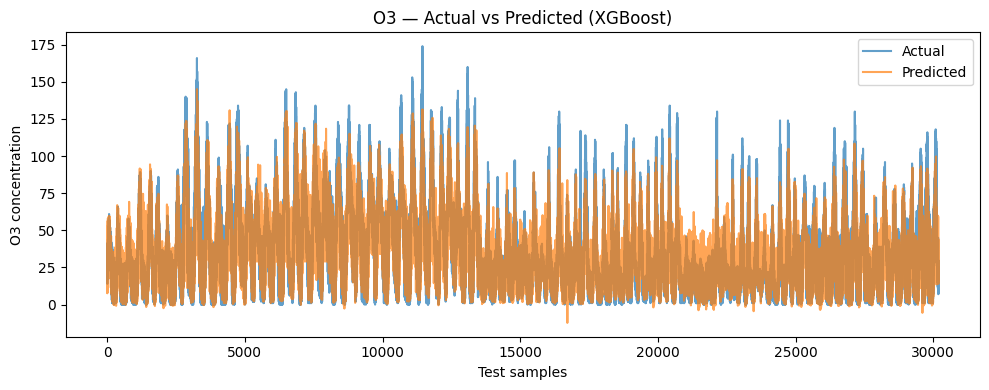

In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error

feature_vars = ['temperature', 'relative humidity', 'wind speed', 'wind direction', 'CO', 'PM10', 'PM25', 'SO2', 'NO', 'NOx', 'NO2', 'PMCO']

# Impute first

X_xgb = airquality_pop[feature_vars].values
y_xgb = airquality_pop['03'].values

# Chronological split per month
train_idx_xgb = []
test_idx_xgb  = []

airquality_pop_reset = airquality_pop.reset_index(drop=True)

for month, group in airquality_pop_reset.groupby(airquality_pop_reset['FECHA'].dt.month):
    split = int(len(group) * 0.75)
    train_idx_xgb.extend(group.index[:split].tolist())
    test_idx_xgb.extend(group.index[split:].tolist())

X_train_xgb, X_test_xgb = X_xgb[train_idx_xgb], X_xgb[test_idx_xgb]
y_train_xgb, y_test_xgb = y_xgb[train_idx_xgb], y_xgb[test_idx_xgb]

# No scaling needed for XGBoost
xgb = XGBRegressor(
    n_estimators=100,      # number of trees
    learning_rate=0.1,     # step size per tree
    max_depth=6,           # tree depth
    random_state=42,
    verbosity=0,
)
xgb.fit(X_train_xgb, y_train_xgb)

y_train_pred = xgb.predict(X_train_xgb)
y_test_pred  = xgb.predict(X_test_xgb)

print(f"Training R²:  {r2_score(y_train_xgb, y_train_pred):.4f}")
print(f"Test R²:      {r2_score(y_test_xgb,  y_test_pred):.4f}")
print(f"Training MAE: {mean_absolute_error(y_train_xgb, y_train_pred):.4f}")
print(f"Test MAE:     {mean_absolute_error(y_test_xgb,  y_test_pred):.4f}")

# Plot feature importance
plt.figure(figsize=(8, 5))
plt.barh(feature_vars, xgb.feature_importances_, color='#ecf723')
plt.xlabel('Importance')
plt.title('Feature Importance — XGBoost predicting O3')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

# Plot actual vs predicted
plt.figure(figsize=(10, 4))
plt.plot(y_test_xgb,  label='Actual',    alpha=0.7)
plt.plot(y_test_pred, label='Predicted', alpha=0.7)
plt.title('O3 — Actual vs Predicted (XGBoost)')
plt.xlabel('Test samples')
plt.ylabel('O3 concentration')
plt.legend()
plt.tight_layout()
plt.show()

Training R²:  0.7462
Test R²:      0.6920
Training MAE: 10.1183
Test MAE:     12.1598


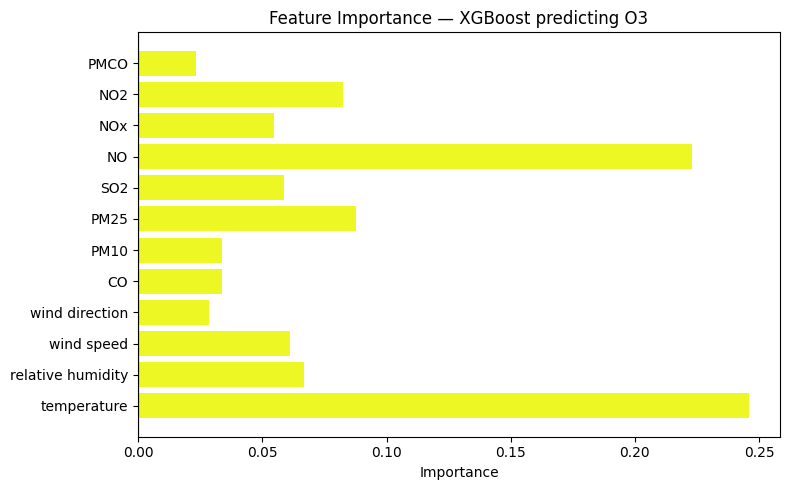

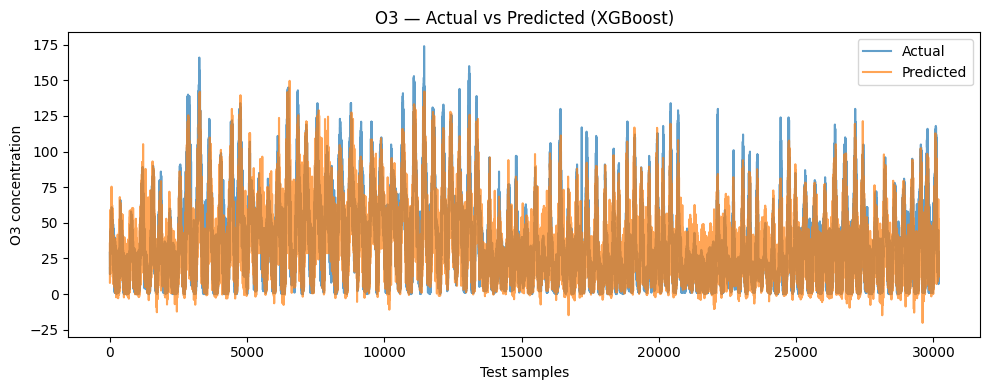

In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error

feature_vars = ['temperature', 'relative humidity', 'wind speed', 'wind direction', 'CO', 'PM10', 'PM25', 'SO2', 'NO', 'NOx', 'NO2', 'PMCO']

# Impute first

X_xgb = airquality_pop[feature_vars].values
y_xgb = airquality_pop['03'].values

# Chronological split per month
train_idx_xgb = []
test_idx_xgb  = []

airquality_pop_reset = airquality_pop.reset_index(drop=True)

for month, group in airquality_pop_reset.groupby(airquality_pop_reset['FECHA'].dt.month):
    split = int(len(group) * 0.75)
    train_idx_xgb.extend(group.index[:split].tolist())
    test_idx_xgb.extend(group.index[split:].tolist())

X_train_xgb, X_test_xgb = X_xgb[train_idx_xgb], X_xgb[test_idx_xgb]
y_train_xgb, y_test_xgb = y_xgb[train_idx_xgb], y_xgb[test_idx_xgb]

# No scaling needed for XGBoost
xgb3 = XGBRegressor(random_state=42)
xgb3.fit(X_train_xgb, y_train_xgb)

y_train_pred = xgb3.predict(X_train_xgb)
y_test_pred  = xgb3.predict(X_test_xgb)

print(f"Training R²:  {r2_score(y_train_xgb, y_train_pred):.4f}")
print(f"Test R²:      {r2_score(y_test_xgb,  y_test_pred):.4f}")
print(f"Training MAE: {mean_absolute_error(y_train_xgb, y_train_pred):.4f}")
print(f"Test MAE:     {mean_absolute_error(y_test_xgb,  y_test_pred):.4f}")

# Plot feature importance
plt.figure(figsize=(8, 5))
plt.barh(feature_vars, xgb3.feature_importances_, color='#ecf723')
plt.xlabel('Importance')
plt.title('Feature Importance — XGBoost predicting O3')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

# Plot actual vs predicted
plt.figure(figsize=(10, 4))
plt.plot(y_test_xgb,  label='Actual',    alpha=0.7)
plt.plot(y_test_pred, label='Predicted', alpha=0.7)
plt.title('O3 — Actual vs Predicted (XGBoost)')
plt.xlabel('Test samples')
plt.ylabel('O3 concentration')
plt.legend()
plt.tight_layout()
plt.show()

Training R²:  0.9712
Test R²:      0.8407
Training MAE: 3.5683
Test MAE:     8.9520


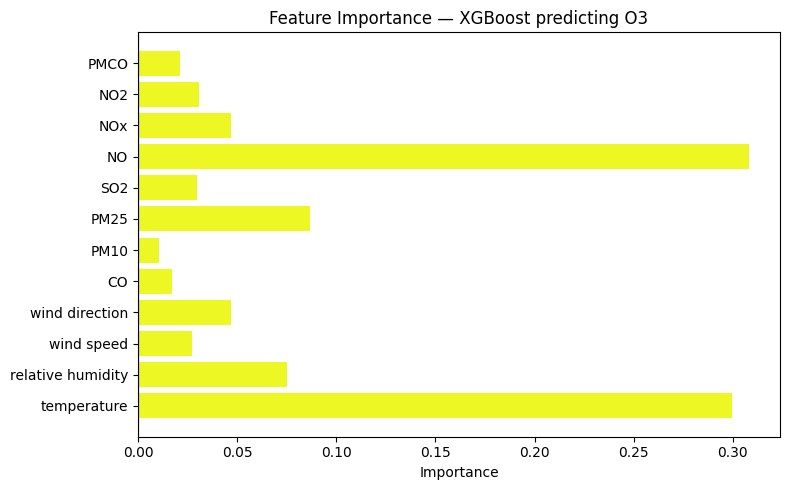

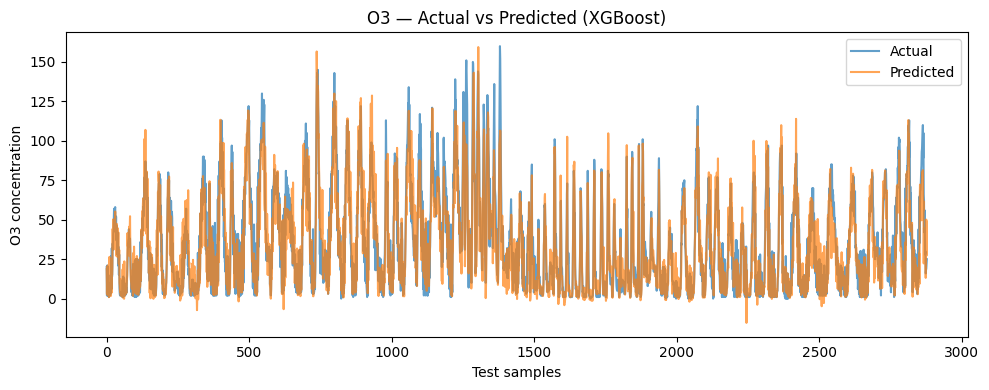

In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error

feature_vars = ['temperature', 'relative humidity', 'wind speed', 'wind direction', 'CO', 'PM10', 'PM25', 'SO2', 'NO', 'NOx', 'NO2', 'PMCO']

# Impute first

X_xgb = airquality_pop_nonan[feature_vars].values
y_xgb = airquality_pop_nonan['03'].values

# Chronological split per month
train_idx_xgb = []
test_idx_xgb  = []

airquality_pop_nonan_reset = airquality_pop_nonan.reset_index(drop=True)

for month, group in airquality_pop_nonan_reset.groupby(airquality_pop_nonan_reset['FECHA'].dt.month):
    split = int(len(group) * 0.75)
    train_idx_xgb.extend(group.index[:split].tolist())
    test_idx_xgb.extend(group.index[split:].tolist())

X_train_xgb, X_test_xgb = X_xgb[train_idx_xgb], X_xgb[test_idx_xgb]
y_train_xgb, y_test_xgb = y_xgb[train_idx_xgb], y_xgb[test_idx_xgb]

# No scaling needed for XGBoost
xgb4 = XGBRegressor(random_state=42)
xgb4.fit(X_train_xgb, y_train_xgb)

y_train_pred = xgb4.predict(X_train_xgb)
y_test_pred  = xgb4.predict(X_test_xgb)

print(f"Training R²:  {r2_score(y_train_xgb, y_train_pred):.4f}")
print(f"Test R²:      {r2_score(y_test_xgb,  y_test_pred):.4f}")
print(f"Training MAE: {mean_absolute_error(y_train_xgb, y_train_pred):.4f}")
print(f"Test MAE:     {mean_absolute_error(y_test_xgb,  y_test_pred):.4f}")

# Plot feature importance
plt.figure(figsize=(8, 5))
plt.barh(feature_vars, xgb4.feature_importances_, color='#ecf723')
plt.xlabel('Importance')
plt.title('Feature Importance — XGBoost predicting O3')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

# Plot actual vs predicted
plt.figure(figsize=(10, 4))
plt.plot(y_test_xgb,  label='Actual',    alpha=0.7)
plt.plot(y_test_pred, label='Predicted', alpha=0.7)
plt.title('O3 — Actual vs Predicted (XGBoost)')
plt.xlabel('Test samples')
plt.ylabel('O3 concentration')
plt.legend()
plt.tight_layout()
plt.show()

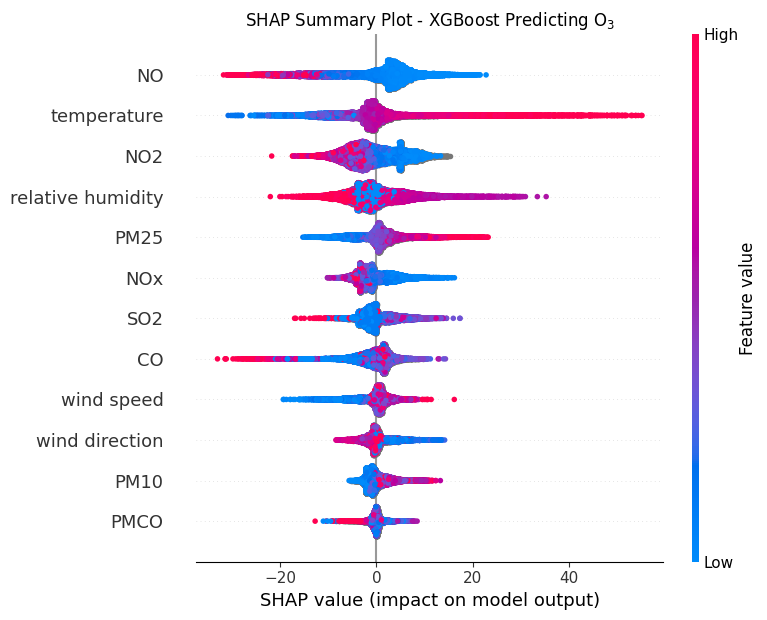

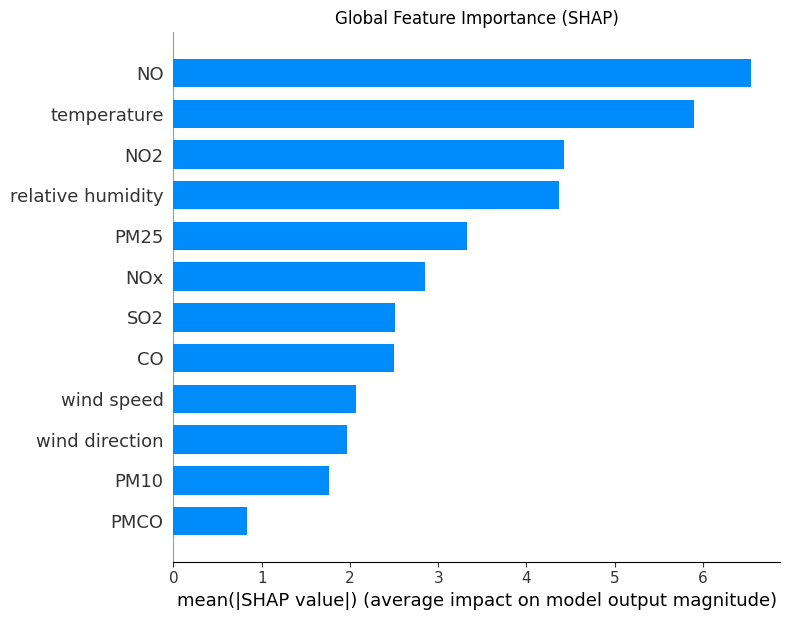

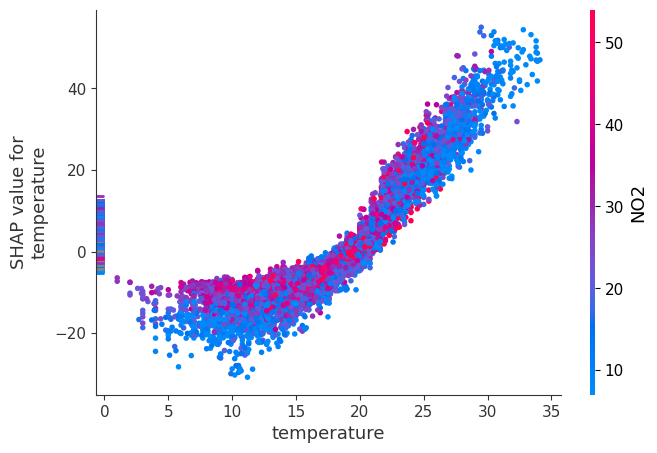

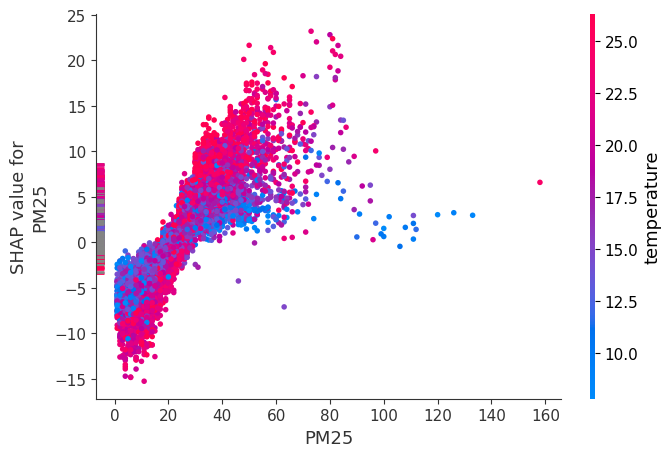

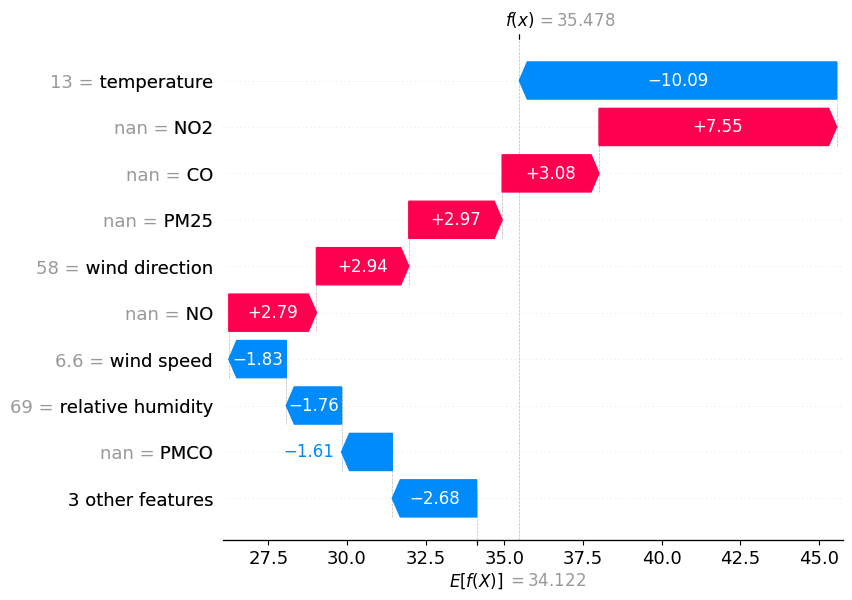

In [ ]:
# ==========================================================
# SHAP analysis for XGBoost
# ==========================================================

import shap
import pandas as pd
import matplotlib.pyplot as plt

# Create DataFrame so SHAP displays feature names
X_train_df = pd.DataFrame(X_train_xgb, columns=feature_vars)
X_test_df = pd.DataFrame(X_test_xgb, columns=feature_vars)

# Create SHAP explainer
explainer = shap.TreeExplainer(xgb3)

# Compute SHAP values for the test set
shap_values = explainer.shap_values(X_test_df)

# ----------------------------------------------------------
# 1. SHAP Summary (Beeswarm) Plot
# ----------------------------------------------------------
plt.figure(figsize=(9, 6))
shap.summary_plot(
    shap_values,
    X_test_df,
    feature_names=feature_vars,
    show=False
)
plt.title("SHAP Summary Plot - XGBoost Predicting O$_3$")
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 2. SHAP Global Importance (Bar Plot)
# ----------------------------------------------------------
plt.figure(figsize=(8, 6))
shap.summary_plot(
    shap_values,
    X_test_df,
    feature_names=feature_vars,
    plot_type="bar",
    show=False
)
plt.title("Global Feature Importance (SHAP)")
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 3. Dependence Plot (Temperature)
# ----------------------------------------------------------
shap.dependence_plot(
    "temperature",
    shap_values,
    X_test_df,
    interaction_index="auto"
)

# ----------------------------------------------------------
# 4. Dependence Plot (PM2.5)
# ----------------------------------------------------------
shap.dependence_plot(
    "PM25",
    shap_values,
    X_test_df,
    interaction_index="auto"
)

# ----------------------------------------------------------
# 5. Waterfall Plot for One Prediction
# ----------------------------------------------------------
sample = 0  # Change to inspect another observation

waterfall_exp = shap.Explanation(
    values=shap_values[sample],
    base_values=explainer.expected_value,
    data=X_test_df.iloc[sample],
    feature_names=feature_vars
)

shap.plots.waterfall(waterfall_exp)

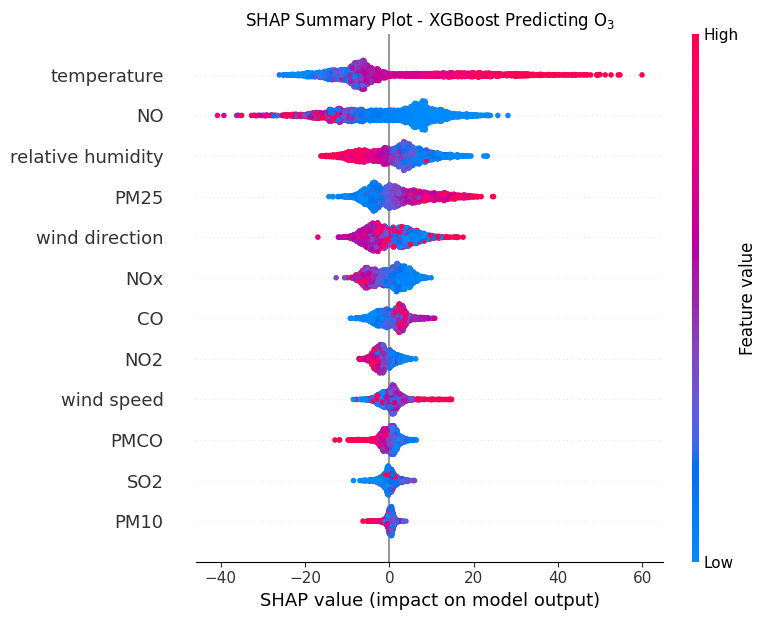

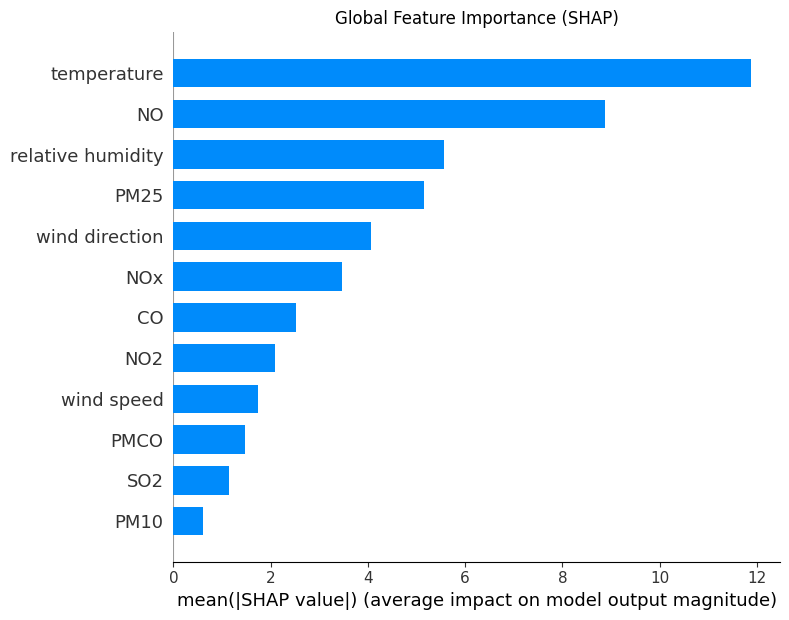

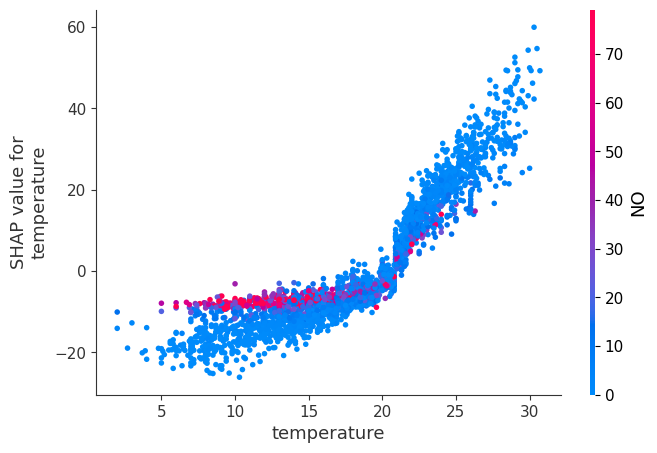

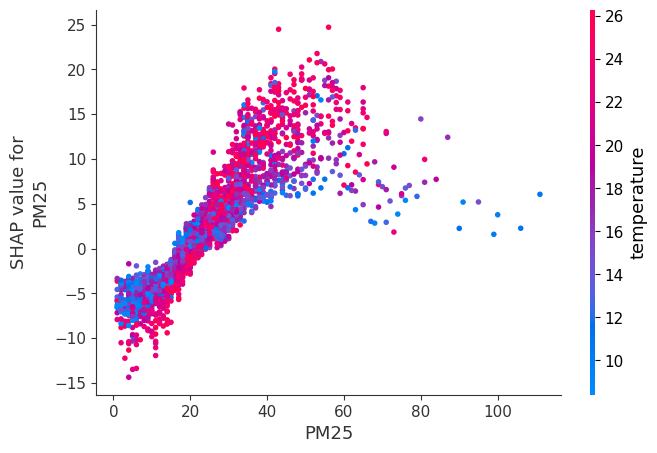

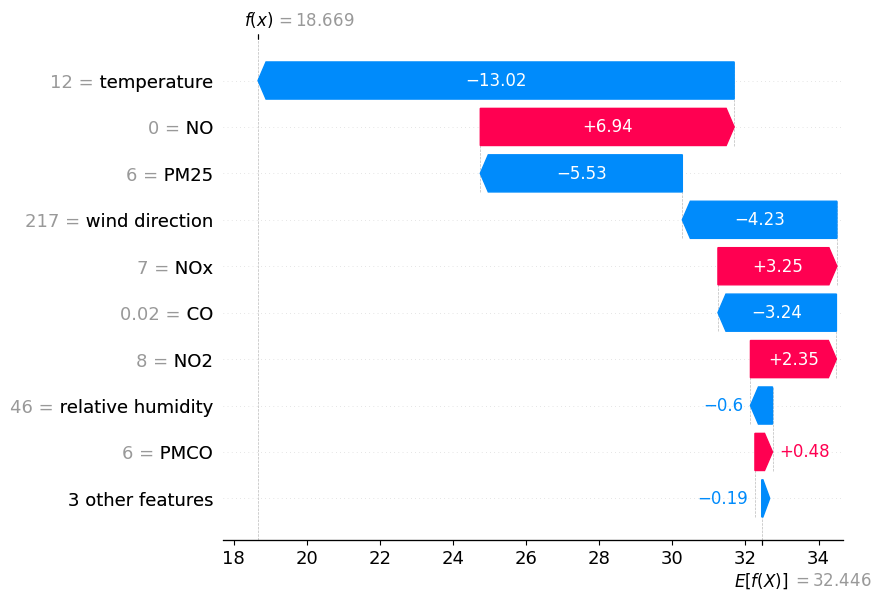

In [ ]:
# ==========================================================
# SHAP analysis for XGBoost
# ==========================================================

import shap
import pandas as pd
import matplotlib.pyplot as plt

# Create DataFrame so SHAP displays feature names
X_train_df = pd.DataFrame(X_train_xgb, columns=feature_vars)
X_test_df = pd.DataFrame(X_test_xgb, columns=feature_vars)

# Create SHAP explainer
explainer = shap.TreeExplainer(xgb4)

# Compute SHAP values for the test set
shap_values = explainer.shap_values(X_test_df)

# ----------------------------------------------------------
# 1. SHAP Summary (Beeswarm) Plot
# ----------------------------------------------------------
plt.figure(figsize=(9, 6))
shap.summary_plot(
    shap_values,
    X_test_df,
    feature_names=feature_vars,
    show=False
)
plt.title("SHAP Summary Plot - XGBoost Predicting O$_3$")
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 2. SHAP Global Importance (Bar Plot)
# ----------------------------------------------------------
plt.figure(figsize=(8, 6))
shap.summary_plot(
    shap_values,
    X_test_df,
    feature_names=feature_vars,
    plot_type="bar",
    show=False
)
plt.title("Global Feature Importance (SHAP)")
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 3. Dependence Plot (Temperature)
# ----------------------------------------------------------
shap.dependence_plot(
    "temperature",
    shap_values,
    X_test_df,
    interaction_index="auto"
)

# ----------------------------------------------------------
# 4. Dependence Plot (PM2.5)
# ----------------------------------------------------------
shap.dependence_plot(
    "PM25",
    shap_values,
    X_test_df,
    interaction_index="auto"
)

# ----------------------------------------------------------
# 5. Waterfall Plot for One Prediction
# ----------------------------------------------------------
sample = 0  # Change to inspect another observation

waterfall_exp = shap.Explanation(
    values=shap_values[sample],
    base_values=explainer.expected_value,
    data=X_test_df.iloc[sample],
    feature_names=feature_vars
)

shap.plots.waterfall(waterfall_exp)

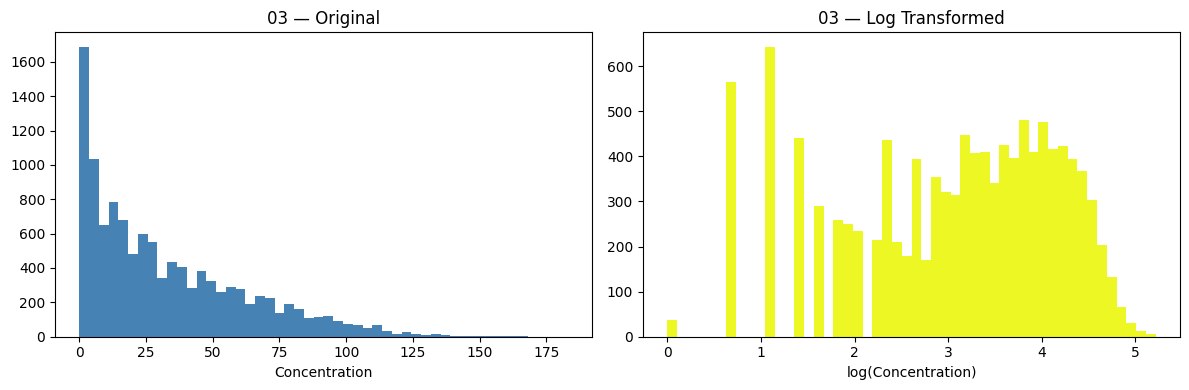

Skewness original:    1.0896
Skewness log:         -0.5069


In [ ]:
pollutant = '03'
data = Cl_whole_poll2[pollutant]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Original
axes[0].hist(data, bins=50, color='steelblue')
axes[0].set_title(f'{pollutant} — Original')
axes[0].set_xlabel('Concentration')

# Log transformed
axes[1].hist(np.log1p(data), bins=50, color='#ecf723')
axes[1].set_title(f'{pollutant} — Log Transformed')
axes[1].set_xlabel('log(Concentration)')

plt.tight_layout()
plt.show()

print(f"Skewness original:    {data.skew():.4f}")
print(f"Skewness log:         {np.log1p(data).skew():.4f}")

  0%|          | 0/300 [00:00<?, ?it/s]

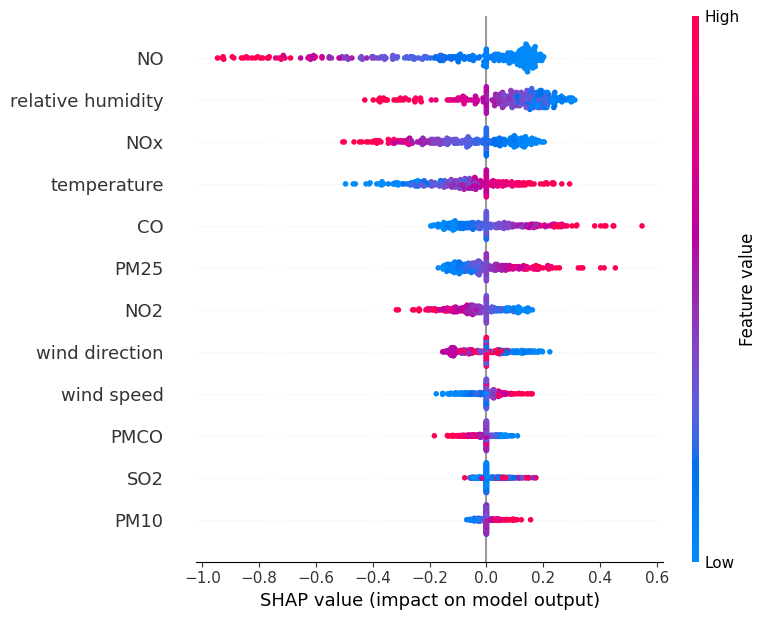

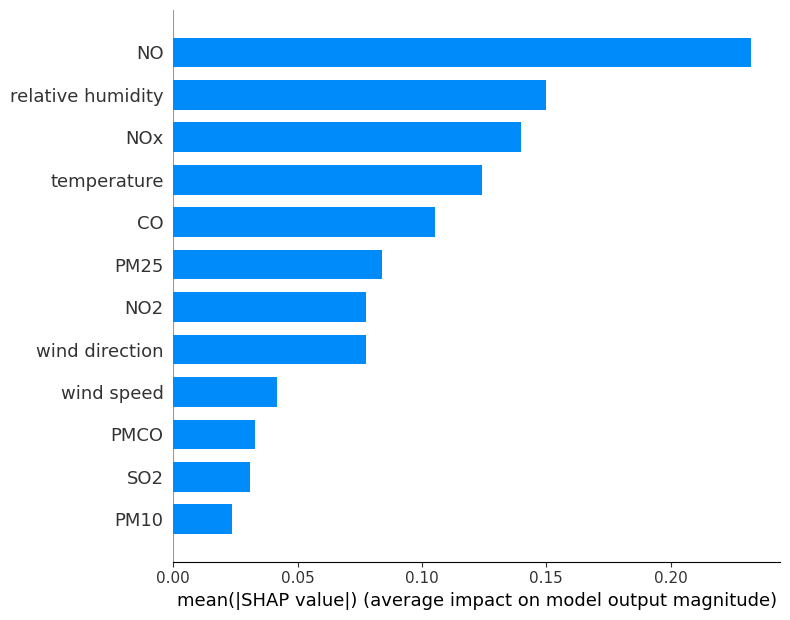

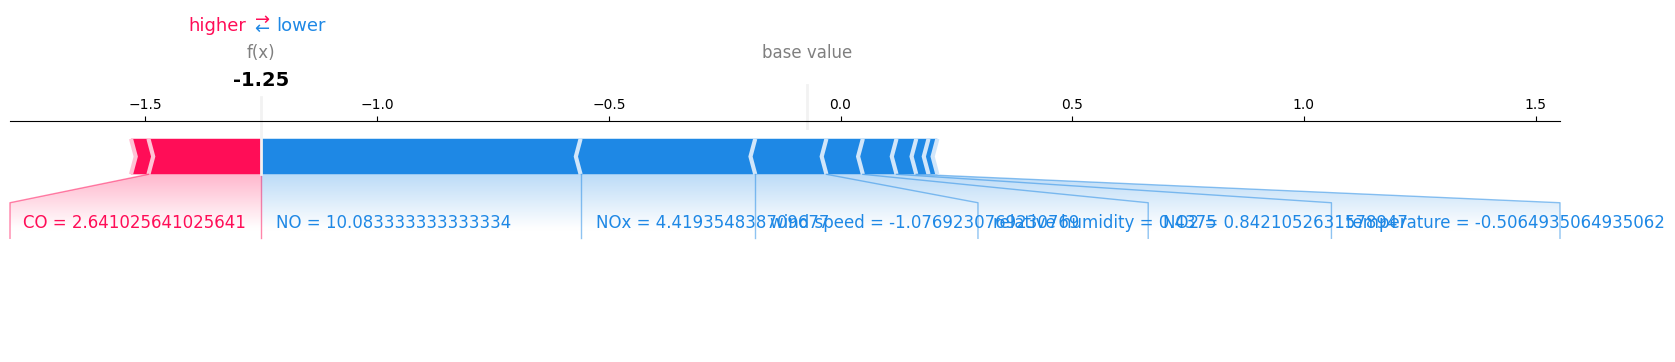

In [ ]:
import shap
import numpy as np
import matplotlib.pyplot as plt

# Use a small background sample (important for speed)
background = X_train_scaled[np.random.choice(X_train_scaled.shape[0], 100, replace=False)]

explainer = shap.KernelExplainer(mlp.predict, background)

# Compute SHAP values for test set (or subset if large)
X_sample = X_test_scaled[:300]   # adjust if needed

shap_values = explainer.shap_values(X_sample)

shap.summary_plot(
    shap_values,
    X_sample,
    feature_names=feature_vars
)

shap.summary_plot(
    shap_values,
    X_sample,
    feature_names=feature_vars,
    plot_type="bar"
)

i = 0  # choose a sample

shap.force_plot(
    explainer.expected_value,
    shap_values[i],
    X_sample[i],
    feature_names=feature_vars,
    matplotlib=True
)

Fitting 1 folds for each of 60 candidates, totalling 60 fits
Best params: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 5}
Training R²: 0.8463
Test R²:     0.7184


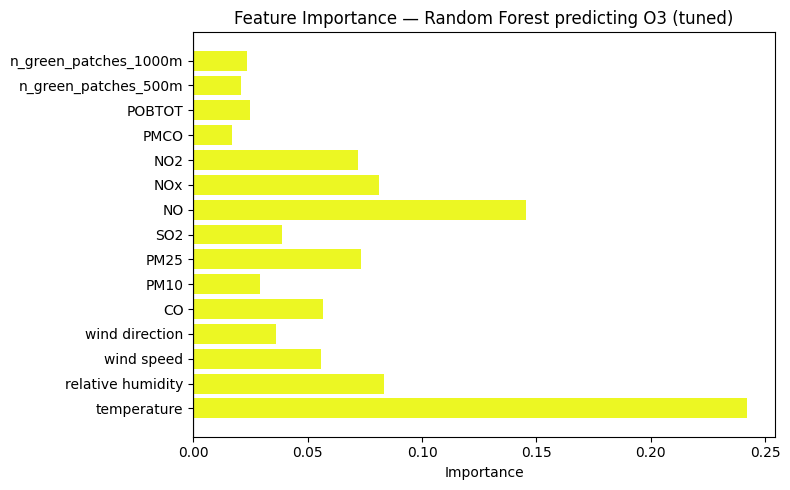

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, PredefinedSplit
import matplotlib.pyplot as plt
import numpy as np

# Features: meteorological variables + other pollutants
feature_vars = ['temperature', 'relative humidity', 'wind speed', 'wind direction', 'CO', 'PM10', 'PM25', 'SO2', 'NO', 'NOx', 'NO2', 'PMCO','POBTOT', 'n_green_patches_500m', 'n_green_patches_1000m']

X_rf = airquality_pop_green[feature_vars].values
y_rf = airquality_pop_green['03'].values

# Chronological split per month
train_idx_rf = []
test_idx_rf  = []

airquality_pop_green_reset = airquality_pop_green.reset_index(drop=True)

for month, group in airquality_pop_green_reset.groupby(airquality_pop_green_reset['FECHA'].dt.month):
    split = int(len(group) * 0.75)
    train_idx_rf.extend(group.index[:split].tolist())
    test_idx_rf.extend(group.index[split:].tolist())

X_train_rf, X_test_rf = X_rf[train_idx_rf], X_rf[test_idx_rf]
y_train_rf, y_test_rf = y_rf[train_idx_rf], y_rf[test_idx_rf]

# --- NEW: build a validation split (last 20% of the training set, per month)
# so GridSearchCV respects chronological order instead of shuffling
val_fold = np.full(len(train_idx_rf), -1)  # -1 = always train
train_idx_arr = np.array(train_idx_rf)

# Mark the most recent ~20% of each month's TRAIN portion as validation
for month, group in airquality_pop_green_reset.groupby(airquality_pop_green_reset['FECHA'].dt.month):
    month_train_mask = np.isin(train_idx_arr, group.index[:int(len(group) * 0.75)])
    month_train_positions = np.where(month_train_mask)[0]
    if len(month_train_positions) > 0:
        val_cut = int(len(month_train_positions) * 0.8)
        val_fold[month_train_positions[val_cut:]] = 0  # 0 = validation fold

ps = PredefinedSplit(test_fold=val_fold)

# --- NEW: constrained parameter grid to control overfitting
param_grid = {
    'max_depth': [6, 8, 10, 12, None],
    'min_samples_leaf': [1, 5, 10, 20],
    'max_features': ['sqrt', 0.5, None],
}

rf_base = RandomForestRegressor(random_state=42, n_estimators=200)

grid_search = GridSearchCV(
    rf_base,
    param_grid,
    cv=ps,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_rf, y_train_rf)

print("Best params:", grid_search.best_params_)

rf = grid_search.best_estimator_

# Fit Random Forest (best estimator, refit on FULL training set)
rf.fit(X_train_rf, y_train_rf)

print(f"Training R²: {rf.score(X_train_rf, y_train_rf):.4f}")
print(f"Test R²:     {rf.score(X_test_rf,  y_test_rf):.4f}")

# Plot feature importance
importances = rf.feature_importances_

plt.figure(figsize=(8, 5))
plt.barh(feature_vars, importances, color='#ecf723')
plt.xlabel('Importance')
plt.title('Feature Importance — Random Forest predicting O3 (tuned)')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()